**Predicting Next-Year Healthcare Spending (Kenzie Lotz)**

**Table of Contents**
1. Setup  
2. Predictors
3. Initial Visualizations 
4. Holdout Split, CV folds, Preprocessing Pipeline
5. Log 2024 Baselines vs OLS Model
6. Regularization Models
7. Forward Selection Model
8. Spline Model
9. Attempting A Two-Part Model
10. Gradient Boosting
11. Model Comparisons
12. Block Comparisons
13. Classification of Top 20% Spenders
14. Final holdout test 
15. Interpretation and summary

Note for Disclosure Document: I wrote the code using our notebooks/labs and a few different Github repositories as a reference, but I did ask Claude Code to read over the dataset and confirm that my outputs (print statements, tables, visualizations) aligned with the collected data values, as well as if my notes on the findings were accurate assessments of what the models tell us about the data.

**1. Setup**

In [154]:
import time
import warnings
from math import factorial
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer, SplineTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, ElasticNet, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (r2_score, root_mean_squared_error, mean_absolute_error, log_loss, roc_auc_score,
                             precision_score, recall_score, accuracy_score, ConfusionMatrixDisplay,
                             RocCurveDisplay)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance

random_seed = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
start_time = time.perf_counter()

import sklearn
assert tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 8), (
    f"This notebook needs scikit-learn >= 1.8 (found {sklearn.__version__}).")
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.0 | pandas 3.0.5


Dataset:

In [155]:
meps = pd.read_csv("../meps_health_expenditures_v1.csv", index_col=0)  
print(meps.shape)
meps.head(3)

(7079, 141)


,dupersid,tot_exp_y2,age,sex,race_eth,marital,education,region,employment,poverty_cat,poverty_pct,insurance,medicaid,medicare,uninsured_all_year,tot_exp_y1,ob_exp_y1,er_exp_y1,ip_exp_y1,rx_exp_y1,hh_exp_y1,oop_exp_y1,ob_visits_y1,op_visits_y1,er_visits_y1,...,ccsr_INJ031,ccsr_INJ064,ccsr_MBD002,ccsr_MBD005,ccsr_MBD007,ccsr_MBD014,ccsr_MUS000,ccsr_MUS006,ccsr_MUS010,ccsr_MUS011,ccsr_MUS025,ccsr_MUS038,ccsr_NVS010,ccsr_NVS016,ccsr_RSP001,ccsr_RSP006,ccsr_RSP007,ccsr_RSP009,ccsr_SKN007,ccsr_SYM006,ccsr_SYM010,ccsr_SYM013,ccsr_SYM016,ccsr_SYM017,high_cost_y2
0,2810003101,12912,66,FEMALE,NON-HISPANIC WHITE ONLY,WIDOWED,HIGH SCHOOL DIPLOMA,SOUTH,EMPLOYED AT RD 2 INT DATE,MIDDLE INCOME,331.19,PUBLIC ONLY,0.0,1.0,0.0,7168,4837,0,0,263,0,1794,36,0,0,...,0,0,1,1,1,0,1,1,1,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0
1,2810006101,875,46,FEMALE,NON-HISPANIC BLACK ONLY,MARRIED,BACHELOR'S DEGREE,SOUTH,EMPLOYED AT RD 2 INT DATE,HIGH INCOME,1348.49,ANY PRIVATE,0.0,0.0,0.0,370,370,0,0,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,2810006102,0,50,MALE,NON-HISPANIC BLACK ONLY,MARRIED,HIGH SCHOOL DIPLOMA,SOUTH,EMPLOYED AT RD 2 INT DATE,HIGH INCOME,1348.49,ANY PRIVATE,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [156]:
meps["education"] = meps["education"].replace("UNDER AGE 16 - INAPPLICABLE", np.nan)
meps["education"].value_counts(dropna=False)

education
HIGH SCHOOL DIPLOMA    2601
BACHELOR'S DEGREE      1494
NO DEGREE               853
MASTER'S DEGREE         768
OTHER DEGREE            717
GED                     293
DOCTORATE DEGREE        291
NaN                      62
Name: count, dtype: int64

**2. Predictors**

I divided the variables into 6 information blocks:

| Block | Information | Name |
|---|---|---|
| `demographics` | age, sex, race/ethnicity, marital status, education, region, employment, income, poverty index, insurance factors | `A_demographics` |
| `prior_use` | Total healthcare expenses, medical visitations (+ duration), and prescriptions (+ refills) (2023 only) | `B_prior_use` |
| `conditions` | high cholesterol, high blood pressure, heart disease/attack, stroke, emphysema, angina, diabetes, arthritis, asthma, number of conditions | `C_medical` (dx part) + `F_conditions` |
| `health_status` | self-rated physical/mental health, limitations (social, cognitive, mobility), SF-12 physical/mental scores, K6 distress, PHQ-2 | `C_medical` (status part) |
| `engagement` | usual source of care, routine checkup, office visits (SAQ), needed a specialist, care rating, cost-related delays, COVID vaccine | `D_engagement` |
| `behavior` | smoker, attitudes toward insurance and risk | `E_behavior_attitudes` |


Note: A few engagement variables also measure use. 'office_visits_saq' is a self-reported count of office visits, and 'care_rating' is missing when someone had no visits or skipped the SAQ. Some of engagement's predictive value will therefore overlap with 'prior_use'.

In [157]:
outcomes = ["tot_exp_y2", "log_tot_exp_y2", "high_cost_y2"]   #2024 values (not used as predictors)
id_cols = ["dupersid"]

blocks = {
    "demographics": ["age", "sex", "race_eth", "marital", "education", "region", "employment",
                     "poverty_cat", "poverty_pct", "insurance", "medicaid", "medicare", "uninsured_all_year"],
    "prior_use": ["tot_exp_y1", "ob_exp_y1", "er_exp_y1", "ip_exp_y1", "rx_exp_y1", "hh_exp_y1", "oop_exp_y1",
                  "ob_visits_y1", "op_visits_y1", "er_visits_y1", "ip_discharges_y1", "ip_nights_y1",
                  "rx_fills_y1", "hh_days_y1"],
    "conditions": ([c for c in meps.columns if c.startswith("dx_")] + ["n_chronic", "n_conditions"]
                   + [c for c in meps.columns if c.startswith("n_cond_") or c.startswith("ccsr_")]),
    "health_status": ["self_rated_health", "self_rated_mental", "any_limitation", "adl_help", "iadl_help",
                      "walk_limit", "cog_limit", "social_limit", "physical_score", "mental_score",
                      "k6_distress", "phq2_depress"],
    "engagement": ["has_usual_source", "routine_checkup", "office_visits_saq", "needed_specialist", "care_rating",
                   "delayed_care_cost", "unafford_care", "delayed_rx_cost", "unafford_rx", "covid_vax_ever"],
    "behavior": ["smoker", "no_need_insurance", "risk_taker"],
}
all_predictors = [c for cols in blocks.values() for c in cols]
block_of = {c: b for b, cols in blocks.items() for c in cols}

pd.DataFrame({"n variables": {b: len(c) for b, c in blocks.items()},
              "first few": {b: ", ".join(c[:4]) + ", ..." for b, c in blocks.items()}})

,n variables,first few
demographics,13,"age, sex, race_eth, marital, ..."
prior_use,14,"tot_exp_y1, ob_exp_y1, er_exp_y1, ip_exp_y1, ..."
conditions,85,"dx_hibp, dx_chd, dx_angina, dx_mi, ..."
health_status,12,"self_rated_health, self_rated_mental, any_limi..."
engagement,10,"has_usual_source, routine_checkup, office_visi..."
behavior,3,"smoker, no_need_insurance, risk_taker, ..."


In [158]:
#keeping every 2024 variable out of the predictors
assert not set(all_predictors) & set(outcomes + id_cols), "an outcome or ID column is in the predictors"
assert not [c for c in all_predictors if "y2" in c], "a _y2 (2024) column is in the predictors"
assert len(all_predictors) == len(set(all_predictors)), "a column is in two blocks"
unused = sorted(set(meps.columns) - set(all_predictors) - set(outcomes) - set(id_cols))
print(f"{len(all_predictors)} predictors in {len(blocks)} blocks. Columns not used as predictors: {unused or 'none'}")

137 predictors in 6 blocks. Columns not used as predictors: none


Notes:
* Variables whose original MEPS names end in "2" come from Round 2 of Panel 28, fielded in 2023. The questionnaire was administered in late 2023 and early 2024. 'office_visits_saq', 'routine_checkup', 'needed_specialist', 'care_rating; ask about "the last 12 months", so for adults who returned the SAQ in early 2024 they overlap slightly with 2024.
* The variables related to medical diagnosis can include conditions first reported at the Panel 28 Round 3 interview, which partly took place in early 2024.
* The 'ccsr_', 'n_cond_', and 'n_conditions' features come from the 2023 condition features.
* The SAQ health scores ('physical_score', 'mental_score', 'k6_distress', 'phq2_depress') use 2- to 4-week recall windows, so for early-2024 respondents they describe early-2024 health. They aren't dropped there, but removing the whole health_status block costs only about 0.001 R².

In [159]:
categorical = ["sex", "race_eth", "marital", "education", "region", "employment",
               "poverty_cat", "insurance", "no_need_insurance", "risk_taker"]
skewed = blocks["prior_use"] #dollars and counts are very right-skewed, so we should use log1p
binary = [c for c in all_predictors
          if c not in categorical and set(meps[c].dropna().unique()) <= {0, 1}]
numeric = [c for c in all_predictors if c not in categorical + skewed + binary]

#columns with more than 5% missing get a "was missing" flag
missing_rate = meps[all_predictors].isna().mean()
flag_massing = missing_rate[missing_rate > 0.05].index.tolist()

print(f"categorical: {len(categorical)} | skewed (log1p): {len(skewed)} | binary: {len(binary)} | other numeric: {len(numeric)}")
print("get a missing flag:", flag_massing)

categorical: 10 | skewed (log1p): 14 | binary: 80 | other numeric: 33
get a missing flag: ['physical_score', 'mental_score', 'k6_distress', 'phq2_depress', 'routine_checkup', 'office_visits_saq', 'needed_specialist', 'care_rating', 'smoker', 'no_need_insurance', 'risk_taker']


In [160]:
#how many of each variable type are in each block
type_counts = pd.DataFrame({
    b: {"categorical": sum(c in categorical for c in cols),
        "binary": sum(c in binary for c in cols),
        "other numeric": sum(c in numeric for c in cols),
        "skewed (log1p)": sum(c in skewed for c in cols)}
    for b, cols in blocks.items()}).T
type_counts["total"] = type_counts.sum(axis=1)
assert (type_counts["total"] == pd.Series({b: len(c) for b, c in blocks.items()})).all(), "a variable has no type"
print(type_counts)

               categorical  binary  other numeric  skewed (log1p)  total
demographics             8       3              2               0     13
prior_use                0       0              0              14     14
conditions               0      62             23               0     85
health_status            0       6              6               0     12
engagement               0       8              2               0     10
behavior                 2       1              0               0      3


**3. Visualizations**

Adults: 7,079
2024 spending: median $2,918, mean $11,163, max $847,517
Share with $0 in 2024: 13.6%
Top 10% of spenders account for 61% of all 2024 spending; the top 1% for 19%
High-cost cutoff (80th percentile of 2024 spending): $13,560
Correlation of 2023 and 2024 spending: raw dollars 0.44, log scale 0.66


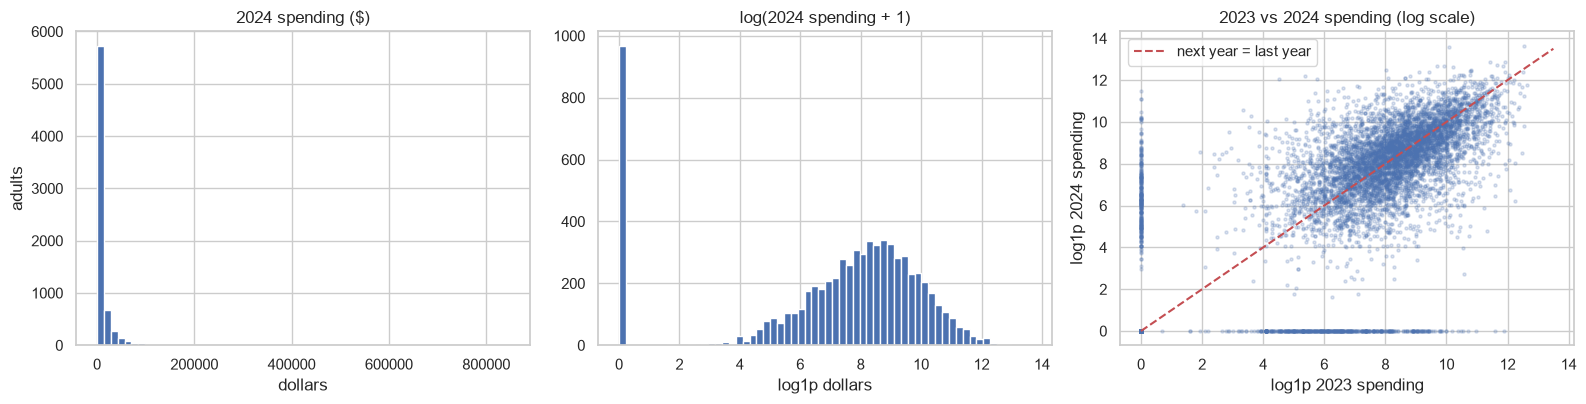

In [161]:
y_dollars = meps["tot_exp_y2"]
ranked = y_dollars.sort_values(ascending=False)
print(f"Adults: {len(meps):,}")
print(f"2024 spending: median ${y_dollars.median():,.0f}, mean ${y_dollars.mean():,.0f}, max ${y_dollars.max():,.0f}")
print(f"Share with $0 in 2024: {(y_dollars == 0).mean():.1%}")
print(f"Top 10% of spenders account for {ranked.head(len(ranked) // 10).sum() / ranked.sum():.0%} of all 2024 spending; "
      f"the top 1% for {ranked.head(len(ranked) // 100).sum() / ranked.sum():.0%}")
print(f"High-cost cutoff (80th percentile of 2024 spending): ${y_dollars.quantile(0.8):,.0f}")
print(f"Correlation of 2023 and 2024 spending: raw dollars {meps['tot_exp_y1'].corr(y_dollars):.2f}, "
      f"log scale {np.log1p(meps['tot_exp_y1']).corr(meps['log_tot_exp_y2']):.2f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].hist(y_dollars, bins=60)
axes[0].set(title="2024 spending ($)", xlabel="dollars", ylabel="adults")
axes[1].hist(meps["log_tot_exp_y2"], bins=60)
axes[1].set(title="log(2024 spending + 1)", xlabel="log1p dollars")
axes[2].scatter(np.log1p(meps["tot_exp_y1"]), meps["log_tot_exp_y2"], s=5, alpha=0.2)
axes[2].plot([0, 13.5], [0, 13.5], "r--", label="next year = last year")
axes[2].set(title="2023 vs 2024 spending (log scale)", xlabel="log1p 2023 spending", ylabel="log1p 2024 spending")
axes[2].legend()
plt.tight_layout()
plt.show()

In [162]:
#missing data by block. almost all of it is the SAQ, which about 31% of adults did not complete.
miss = pd.DataFrame({b: {"avg % missing": meps[c].isna().mean().mean() * 100,
                         "max % missing": meps[c].isna().mean().max() * 100}
                     for b, c in blocks.items()}).T.round(1)
display(miss)

saq_status = meps["physical_score"].isna().map({False: "completed SAQ", True: "no SAQ"})
print("log 2024 spending by SAQ status:")
print(meps.groupby(saq_status)["log_tot_exp_y2"].agg(["count", "mean"]).round(2))
print("\nShare with $0 in 2024 by SAQ status:")
print((meps["tot_exp_y2"] == 0).groupby(saq_status).mean().round(3))

,avg % missing,max % missing
demographics,0.1,0.9
prior_use,0.0,0.3
conditions,0.0,1.6
health_status,10.8,33.1
engagement,15.3,49.1
behavior,32.6,32.8


log 2024 spending by SAQ status:
                count  mean
physical_score             
completed SAQ    4908  7.48
no SAQ           2171  6.21

Share with $0 in 2024 by SAQ status:
physical_score
completed SAQ    0.106
no SAQ           0.205
Name: tot_exp_y2, dtype: float64


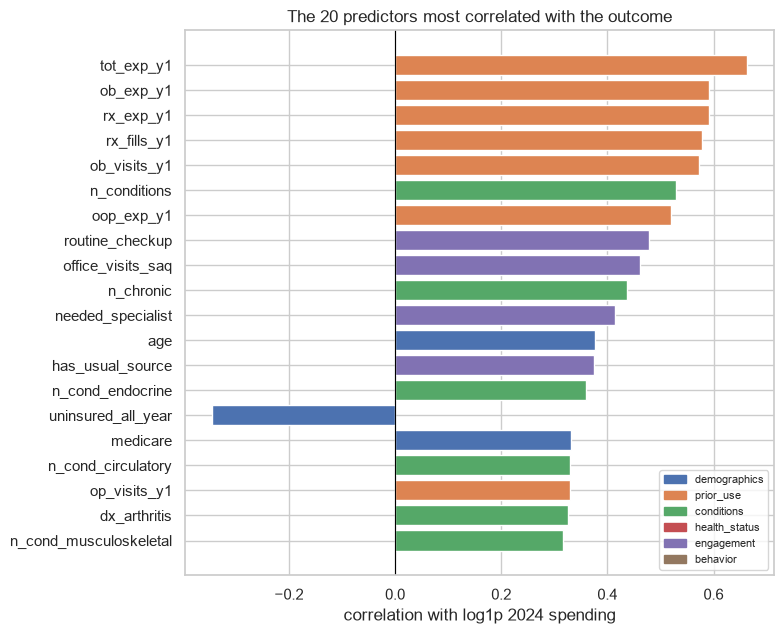

any 2023 condition records,False,True
any 2023 spending,,
False,759,2
True,760,5558


In [163]:
#correlation of each numeric / 0-1 predictor with log 2024 spending (dollars and counts log1p'd first), colored by block
num_cols = [c for c in all_predictors if c not in categorical]
eda = meps[num_cols].copy()
eda[skewed] = np.log1p(eda[skewed])
r = eda.corrwith(meps["log_tot_exp_y2"]).dropna()
top = r.reindex(r.abs().sort_values(ascending=False).index).head(20)[::-1]
palette = dict(zip(blocks, sns.color_palette(n_colors=len(blocks))))

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top.index, top.values, color=[palette[block_of[c]] for c in top.index])
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="correlation with log1p 2024 spending", title="The 20 predictors most correlated with the outcome")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=col) for col in palette.values()], labels=list(palette),
          fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

pd.crosstab(meps["tot_exp_y1"] > 0, meps["n_conditions"] > 0,
            rownames=["any 2023 spending"], colnames=["any 2023 condition records"])

* The top 10% of adults account for 61% of 2024 spending and the top 1% for 19%. In raw dollars the histogram is one tall bar near $0. On the log scale it is much closer to a bell shape, plus a spike of $0 spenders (13.6%). 
* 2023 and 2024 spending move together strongly on the log scale (r = 0.66) and much less so in raw dollars (r = 0.44), because a few very large bills (ex: a surgery or a hospital stay) don't repeat from year to year.
* In the scatter plot, the cloud falls below the "next year = last year" line for high 2023 spenders and above it for low spenders, so "next year = last year" will not be the best possible predictor.
* **THE MISSING DATA IS NOT RANDOM.** Adults who skipped the SAQ have lower 2024 spending (mean log 6.21 vs 7.48) and are about twice as likely to spend $0 (20.5% vs 10.6%). Dropping these adults would bias the sample, and imputing alone would hide a useful signal, so the pipeline should impute and add "was missing" flags.
* The top 5 predictors most correlated with log 2024 spending are all prior use metrics, then condition and engagement metrics make up the bottom half of the top 10. Being uninsured all year has the strongest negative correlation. No health status or behavior metrics are in the top 20.
* The crosstab shows that only 2 of the 761 adults with $0 in 2023 have any record in the 2023 conditions file, versus 5,558 of 6,318 adults who had some spending. MEPS records conditions mostly when they come up at a medical event. So 'n_conditions', the 'n_cond_*' counts, and the 'ccsr_' variables partly measure whether someone used care in 2023. The self-reported diagnoses are asked of everyone. 

**4. Preprocessing (Hold Out Set, CV Folds, and Pipeline Set-Up**

* One 80/20 split. I stratified on 'high_cost_y2', so the regression and classification models share the same test adults.
* All model choices come from 5-fold CV on the training set, with the same folds for every model. Because the folds are shared, we can also compare two models fold by fold (a paired comparison), which is more precise than comparing their separate means.
* All imputation, scaling, one-hot encoding is done with a pipeline, so it is re-fit on the training part of every fold and never sees the validation rows.

In [164]:
X = meps[all_predictors]
y_log = meps["log_tot_exp_y2"]
y_high = meps["high_cost_y2"]

idx_train, idx_test = train_test_split(meps.index, test_size=0.2, stratify=y_high, random_state=random_seed)
X_train, X_test = X.loc[idx_train], X.loc[idx_test]
ylog_train, ylog_test = y_log.loc[idx_train], y_log.loc[idx_test]
yhigh_train, yhigh_test = y_high.loc[idx_train], y_high.loc[idx_test]
ydol_train, ydol_test = meps.loc[idx_train, "tot_exp_y2"], meps.loc[idx_test, "tot_exp_y2"]

print(f"Training set: {len(X_train):,} adults (high-cost rate {yhigh_train.mean():.3f})")
print(f"Test set:     {len(X_test):,} adults (high-cost rate {yhigh_test.mean():.3f})")

cv_reg = KFold(n_splits=5, shuffle=True, random_state=random_seed)
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_seed)

Training set: 5,663 adults (high-cost rate 0.200)
Test set:     1,416 adults (high-cost rate 0.200)


In [ ]:
def make_preprocessor(cols):
    #preprocessing for any subset of predictor columns
    #skewed dollars/counts are log1p and standardized using median impute
    #other numeric are standardized using median impute (+ missing flag if the column is > 5% missing)
    #binary 0/1 are standardized using most-frequent impute (+ missing flag), left unscaled as in class
    #categorical are standardized using most-frequent impute. one-hot drops the first level
    def pick(group, flagged):
        return [c for c in cols if c in group and (c in flag_massing) == flagged]

    log1p = FunctionTransformer(np.log1p, feature_names_out="one-to-one")
    onehot = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
    transformers = [
        ("skewed",   make_pipeline(log1p, StandardScaler(), SimpleImputer(strategy="median")),
                     [c for c in cols if c in skewed]),
        ("num",      make_pipeline(StandardScaler(), SimpleImputer(strategy="median")), pick(numeric, False)),
        ("num_flag", make_pipeline(StandardScaler(), SimpleImputer(strategy="median", add_indicator=True)),
                     pick(numeric, True)),
        ("bin",      SimpleImputer(strategy="most_frequent"), pick(binary, False)),
        ("bin_flag", SimpleImputer(strategy="most_frequent", add_indicator=True), pick(binary, True)),
        ("cat",      make_pipeline(SimpleImputer(strategy="most_frequent"), onehot), pick(categorical, False)),
        ("cat_flag", make_pipeline(SimpleImputer(strategy="constant", fill_value="missing"), onehot),
                     pick(categorical, True)),
    ]
    return ColumnTransformer([t for t in transformers if t[2]], verbose_feature_names_out=False)


def feature_block(name):
    #which block does a model column (after one-hot encoding/missing flags) come from?
    raw = name.replace("missingindicator_", "")
    matches = [c for c in all_predictors if raw == c or raw.startswith(c + "_")]
    return block_of[max(matches, key=len)] if matches else "?"


pre_all = make_preprocessor(all_predictors).fit(X_train)
feature_names = pre_all.get_feature_names_out()
print(f"{len(all_predictors)} raw predictors -> {len(feature_names)} model columns after one-hot encoding and missing flags")
pd.Series([feature_block(f) for f in feature_names]).value_counts().rename("model columns per block")

137 raw predictors -> 172 model columns after one-hot encoding and missing flags


conditions       85
demographics     31
health_status    16
prior_use        14
engagement       14
behavior         12
Name: model columns per block, dtype: int64

**5. Regression: predicting log 2024 spending**

The metrics are RMSE and R² on the log1p scale, both from 5-fold CV on the training set. 

**Baselines**
1. Mean only: predict the training mean for everyone (R² ≈ 0).
2. Next year = last year: predict log1p(2024 spending) = log1p(2023 spending). Nothing is fit.
3. Simple regression on log 2023 spending: Both the slope and intercept are fit so it can regress toward the mean.

In [166]:
FOLD_R2 = {}   #per-fold R2 of every model we score

def cv_reg_scores(name, model, cols=all_predictors):
    #5-fold CV RMSE and R2 on training 
    res = cross_validate(model, X_train[cols], ylog_train, cv=cv_reg, n_jobs=-1,
                         scoring=["neg_root_mean_squared_error", "r2"])
    FOLD_R2[name] = res["test_r2"]
    return {"model": name,
            "CV RMSE": -res["test_neg_root_mean_squared_error"].mean(),
            "RMSE sd": res["test_neg_root_mean_squared_error"].std(),
            "CV R2": res["test_r2"].mean(),
            "R2 sd": res["test_r2"].std()}

reg_results = {}   #model name + CV scores

def add_reg(row):
    reg_results[row["model"]] = row

def reg_table_now():
    return pd.DataFrame(list(reg_results.values())).set_index("model")

persist_train = np.log1p(X_train["tot_exp_y1"])
add_reg(cv_reg_scores("Mean only", DummyRegressor()))
add_reg({"model": "Next year = last year (no fitting)",
         "CV RMSE": root_mean_squared_error(ylog_train, persist_train), "RMSE sd": np.nan,
         "CV R2": r2_score(ylog_train, persist_train), "R2 sd": np.nan})
add_reg(cv_reg_scores("Simple regression on log 2023 spending",
                      make_pipeline(make_preprocessor(["tot_exp_y1"]), LinearRegression()), cols=["tot_exp_y1"]))
reg_table_now().round(3)

,CV RMSE,RMSE sd,CV R2,R2 sd
model,,,,
Mean only,3.220,0.031,-0.000,0.000
Next year = last year (no fitting),2.548,NaN,0.374,NaN
Simple regression on log 2023 spending,2.410,0.046,0.440,0.018


**Baselines:**
* With no fitting at all, "next year = last year" already explains about 37% of the variance in log 2024 spending.
* Letting a regression fit the line helps (CV R² 0.44). The fitted slope is about 0.72, below 1, so it pulls predictions toward the mean, matching the pattern above.


**Multiple linear Regression (OLS) with every block**

In [167]:
add_reg(cv_reg_scores("OLS, all blocks", make_pipeline(make_preprocessor(all_predictors), LinearRegression())))
reg_table_now().round(3)

,CV RMSE,RMSE sd,CV R2,R2 sd
model,,,,
Mean only,3.220,0.031,-0.000,0.000
Next year = last year (no fitting),2.548,NaN,0.374,NaN
Simple regression on log 2023 spending,2.410,0.046,0.440,0.018
"OLS, all blocks",2.209,0.038,0.529,0.014


In [168]:
#check VIFs for the numeric predictors. missing values are median-filled
vif_cols = skewed + numeric
Xv = X_train[vif_cols].copy()
Xv[skewed] = np.log1p(Xv[skewed])
Xv = sm.add_constant(Xv.fillna(Xv.median()))
vifs = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=vif_cols, name="VIF")
vifs.sort_values(ascending=False).head(12).round(1)

n_conditions                167.4
ip_discharges_y1             16.4
ip_exp_y1                    14.2
n_cond_musculoskeletal       10.8
rx_fills_y1                   8.9
er_visits_y1                  8.5
n_cond_endocrine              8.5
n_cond_circulatory            7.8
er_exp_y1                     7.4
rx_exp_y1                     7.4
n_cond_mental_behavioral      6.9
ip_nights_y1                  6.4
Name: VIF, dtype: float64

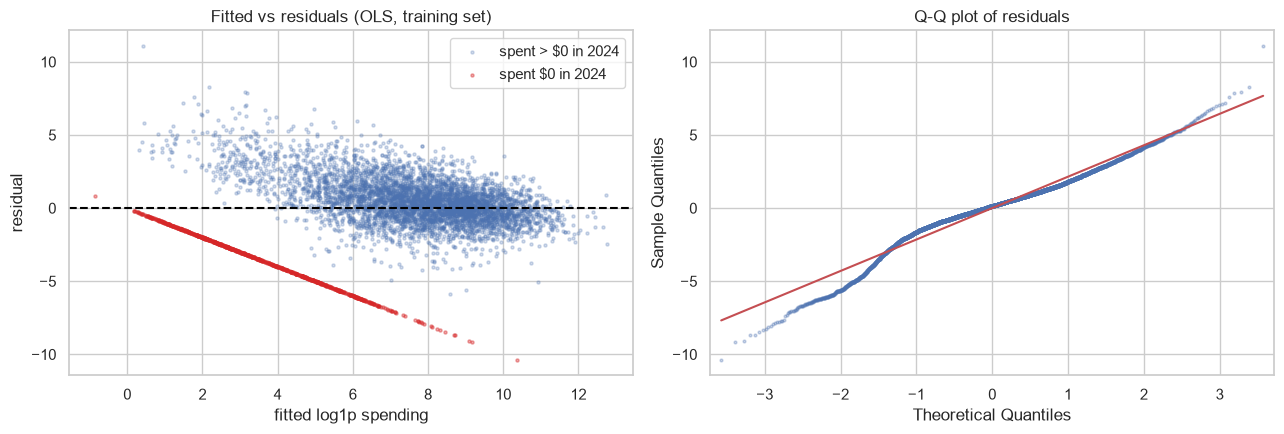

In [169]:
#residuals for OLS fit on the full training set 
ols_fit = make_pipeline(make_preprocessor(all_predictors), LinearRegression()).fit(X_train, ylog_train)
fitted = ols_fit.predict(X_train)
resid = ylog_train - fitted
zero_2024 = (ydol_train == 0).to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(fitted[~zero_2024], resid[~zero_2024], s=5, alpha=0.25, label="spent > $0 in 2024")
axes[0].scatter(fitted[zero_2024], resid[zero_2024], s=5, alpha=0.4, color="tab:red", label="spent $0 in 2024")
axes[0].axhline(0, color="black", ls="--")
axes[0].set(xlabel="fitted log1p spending", ylabel="residual", title="Fitted vs residuals (OLS, training set)")
axes[0].legend()
sm.qqplot(resid, line="s", ax=axes[1], markersize=2, alpha=0.3)
axes[1].set_title("Q-Q plot of residuals")
plt.tight_layout()
plt.show()

**Notes**

* Using every block raises CV R² from 0.44 (2023 spending only) to 0.53, so the other 136 predictors add about 9 points of R² together.
* 'n_conditions' has a VIF of about 167 because it is very close to the sum of 'n_cond_*'. Inpatient discharges and inpatient spending (VIF 16 and 14) also overlap heavily. 
* The residual points form a perfectly straight diagonal line. These are the adults who spent $0 in 2024 (their actual value is 0, so each residual is just minus its fitted value). Many adults predicted to spend almost nothing actually spent a few thousand dollars, giving residuals of 3 to 8. The Q-Q plot has a heavy lower tail made of the zeros. Both problems trace back to the spike at $0.

**6. Regularization**


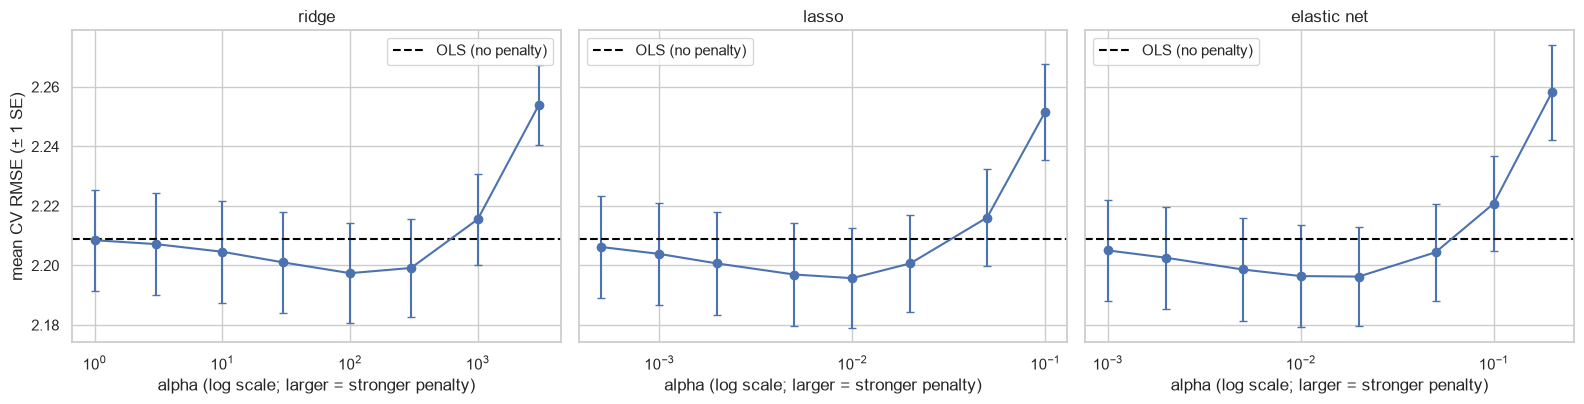

,penalty,alpha,CV RMSE,RMSE sd,CV R2,R2 sd
0,ridge,1.0000,2.2085,0.0381,0.5293,0.0144
1,ridge,3.0000,2.2072,0.0381,0.5299,0.0144
2,ridge,10.0000,2.2046,0.0382,0.5310,0.0145
3,ridge,30.0000,2.2010,0.0381,0.5325,0.0146
4,ridge,100.0000,2.1974,0.0377,0.5340,0.0146
5,ridge,300.0000,2.1991,0.0366,0.5333,0.0141
6,ridge,1000.0000,2.2155,0.0341,0.5263,0.0127
7,ridge,3000.0000,2.2539,0.0303,0.5098,0.0102
8,lasso,0.0005,2.2062,0.0382,0.5303,0.0144
9,lasso,0.0010,2.2039,0.0381,0.5313,0.0145


In [170]:
def make_linear(kind, alpha, cols=all_predictors):
    est = {"ridge": Ridge(alpha=alpha),
           "lasso": Lasso(alpha=alpha, max_iter=50000),
           "elastic net": ElasticNet(alpha=alpha, l1_ratio=0.5, max_iter=50000)}[kind]
    return make_pipeline(make_preprocessor(cols), est)

alpha_grid = {
    "ridge":       [1, 3, 10, 30, 100, 300, 1000, 3000],
    "lasso":       [0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1],
    "elastic net": [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2],
}
rows = []
for kind, alphas in alpha_grid.items():
    for a in alphas:
        r = cv_reg_scores(f"{kind} alpha={a}", make_linear(kind, a))
        rows.append({"penalty": kind, "alpha": a, **{k: v for k, v in r.items() if k != "model"}})
pen_results = pd.DataFrame(rows)

ols_rmse = reg_table_now().loc["OLS, all blocks", "CV RMSE"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, (kind, g) in zip(axes, pen_results.groupby("penalty", sort=False)):
    ax.errorbar(g["alpha"], g["CV RMSE"], yerr=g["RMSE sd"] / np.sqrt(5), marker="o", capsize=3)
    ax.axhline(ols_rmse, color="black", ls="--", label="OLS (no penalty)")
    ax.set(xscale="log", title=kind, xlabel="alpha (log scale; larger = stronger penalty)")
    ax.legend()
axes[0].set_ylabel("mean CV RMSE (± 1 SE)")
plt.tight_layout()
plt.show()
pen_results.round(4)

In [171]:
#best alpha for each penalty give us the lowest mean CV RMSE for lasso.
#applied the one-SE rule from multinomial KNN
best = pen_results.loc[pen_results.groupby("penalty")["CV RMSE"].idxmin()].set_index("penalty")
alpha_ridge, alpha_lasso, alpha_enet = best.loc["ridge", "alpha"], best.loc["lasso", "alpha"], best.loc["elastic net", "alpha"]

lasso_rows = pen_results[pen_results["penalty"] == "lasso"]
cutoff = best.loc["lasso", "CV RMSE"] + best.loc["lasso", "RMSE sd"] / np.sqrt(5)
alpha_lasso_1se = lasso_rows.loc[lasso_rows["CV RMSE"] <= cutoff, "alpha"].max()

print(f"Best ridge alpha: {alpha_ridge} | Best lasso alpha: {alpha_lasso} (One-SE: {alpha_lasso_1se}) | Best elastic net alpha: {alpha_enet}")

for name, kind, a in [(f"Ridge (alpha={alpha_ridge})", "ridge", alpha_ridge),
                      (f"Lasso (alpha={alpha_lasso})", "lasso", alpha_lasso),
                      (f"Lasso one-SE (alpha={alpha_lasso_1se})", "lasso", alpha_lasso_1se),
                      (f"Elastic net (alpha={alpha_enet})", "elastic net", alpha_enet)]:
    add_reg(cv_reg_scores(name, make_linear(kind, a)))
reg_table_now().round(3)

Best ridge alpha: 100.0 | Best lasso alpha: 0.01 (One-SE: 0.02) | Best elastic net alpha: 0.02


,CV RMSE,RMSE sd,CV R2,R2 sd
model,,,,
Mean only,3.220,0.031,-0.000,0.000
Next year = last year (no fitting),2.548,NaN,0.374,NaN
Simple regression on log 2023 spending,2.410,0.046,0.440,0.018
"OLS, all blocks",2.209,0.038,0.529,0.014
Ridge (alpha=100.0),2.197,0.038,0.534,0.015
Lasso (alpha=0.01),2.196,0.038,0.535,0.015
Lasso one-SE (alpha=0.02),2.201,0.037,0.533,0.014
Elastic net (alpha=0.02),2.196,0.037,0.534,0.014


We fit the one-SE lasso on the full training set and look at which columns survive. Numeric predictors are standardized, so their coefficient is the change in log spending for every 1 standard deviation. Binary predictors are not scaled, so their coefficient is the yes-vs-no difference. e^coef − 1 is roughly the % change in the typical value of spending + 1. With 13.6% of adults at $0, this mixes whether someone spends anything with how much, so this isn't a perfect metric.

In [172]:
lasso_fit = make_linear("lasso", alpha_lasso_1se).fit(X_train, ylog_train)
lasso_coefs = pd.DataFrame({"coef": lasso_fit[-1].coef_}, index=lasso_fit[0].get_feature_names_out())
lasso_coefs["block"] = [feature_block(f) for f in lasso_coefs.index]
lasso_coefs["kept"] = lasso_coefs["coef"] != 0

print(f"Lasso (alpha={alpha_lasso_1se}) keeps {lasso_coefs['kept'].sum()} of {len(lasso_coefs)} model columns")
display(lasso_coefs.groupby("block").agg(columns=("coef", "size"), kept=("kept", "sum"))
        .assign(share_kept=lambda d: (d["kept"] / d["columns"]).round(2)))

top = lasso_coefs[lasso_coefs["kept"]].sort_values("coef", key=abs, ascending=False).head(20)
top.assign(pct_change=(np.exp(top["coef"]) - 1).round(3)).round(3)

Lasso (alpha=0.02) keeps 43 of 172 model columns


,columns,kept,share_kept
block,,,
behavior,12,2,0.17
conditions,85,12,0.14
demographics,31,10,0.32
engagement,14,6,0.43
health_status,16,3,0.19
prior_use,14,10,0.71


,coef,block,kept,pct_change
tot_exp_y1,1.069,prior_use,True,1.913
uninsured_all_year,-0.904,demographics,True,-0.595
rx_exp_y1,0.420,prior_use,True,0.522
race_eth_NON-HISPANIC WHITE ONLY,0.384,demographics,True,0.468
ob_visits_y1,0.317,prior_use,True,0.374
region_SOUTH,-0.230,demographics,True,-0.205
n_chronic,0.215,conditions,True,0.240
routine_checkup,0.212,engagement,True,0.236
age,0.207,demographics,True,0.230
missingindicator_care_rating,-0.178,engagement,True,-0.163


**Notes**
* All three penalties out perform OLS, but only slightly. CV RMSE drops from 2.209 to about 2.196, and R² rises from 0.529 to 0.535. The paired comparison in 4.8 puts OLS about 0.005 R² below ridge, roughly twice the fold-to-fold standard deviation, so the gain is small but consistent. Since our data has 5,700 adults and 172 columns, the unpenalized model doesn't have much room to overfit.
* The best ridge, lasso, and elastic net are essentially tied. Lasso (one-SE, alpha = 0.02) keeps 43 of 172 columns. It keeps 10 of the 14 prior-use columns but only 12 of the 85 condition columns. Once spending is in the model, most specific diagnoses add little.
* Holding all other variables fixed:
  * 'tot_exp_y1' with 1 SD of log 2023 spending has about +1.07 log units in 2024, making it the largest term.
  * "Uninsured" (all of 2023) has about 0.9 lower log1p on spending in 2024. Much of this is about spending nothing at all (53% of uninsured adults had $0 in 2024 vs 10.5% of insured adults). (This column is identical to 'insurance' = UNINSURED. Lasso puts almost all the weight on 'uninsured_all_year'.)
  * Prescription spending and office visits add information beyond the total. 'ip_exp_y1' is negative once total spending is included.
  * Engagement metrics 'routine_checkup', 'has_usual_source', and 'covid_vax_ever' are all positive. The care-rating missing flag is negative because it marks adults who skipped the SAQ (62% of those flagged) or reported no office visits (34%), and both groups spend less.
  * Older ages and being non-Hispanic White (vs Hispanic, the reference level) go with higher spending. Living in the South (vs the Midwest, the reference level) goes with lower spending.

**7. Forward selection**

Note: Forward selection is a  greedy algorithm, so at each step it adds the column that most improves the 5-fold CV RMSE.

In [173]:
start = time.perf_counter()
forward = make_pipeline(make_preprocessor(all_predictors),
                        SequentialFeatureSelector(LinearRegression(), n_features_to_select=10, direction="forward",
                                                  cv=cv_reg, scoring="neg_root_mean_squared_error"),
                        LinearRegression())
forward.fit(X_train, ylog_train)
picked = forward[:-1].get_feature_names_out()
print(f"Forward selection took {time.perf_counter() - start:.0f} s")

Xt_train = pd.DataFrame(pre_all.transform(X_train), columns=feature_names, index=X_train.index)
r2_10 = cross_validate(LinearRegression(), Xt_train[picked], ylog_train, cv=cv_reg, scoring="r2")["test_score"]
print(f"CV R2 with only these 10 columns: {r2_10.mean():.3f}  (all 172 columns, OLS: {FOLD_R2['OLS, all blocks'].mean():.3f})")
pd.DataFrame({"block": [feature_block(f) for f in picked], "coef": forward[-1].coef_.round(3)}, index=picked)

Forward selection took 29 s
CV R2 with only these 10 columns: 0.527  (all 172 columns, OLS: 0.529)


,block,coef
tot_exp_y1,prior_use,1.061
rx_exp_y1,prior_use,0.432
ob_visits_y1,prior_use,0.401
rx_fills_y1,prior_use,0.108
age,demographics,0.224
n_chronic,conditions,0.211
missingindicator_care_rating,engagement,-0.396
uninsured_all_year,demographics,-1.278
race_eth_NON-HISPANIC WHITE ONLY,demographics,0.459
region_SOUTH,demographics,-0.344


**Notes**
* The 10 picks are 4 prior-use columns (total, Rx spending, office visits, Rx fills), 4 demographics (age, uninsured all year, race, region), 'n_chronic', and the care-rating missing flag (no SAQ or no office visits). These largely match lasso's biggest coefficients.
* These 10 columns alone reach CV R² 0.527, nearly the 0.529 of OLS with all 172 columns. Most of the other columns add very little on their own.

**8. Splines**

I swapped the straight-line terms for age and log 2023 total spending with cubic B-splines (5 knots at quantiles). Every other predictor stays linear, and the ridge penalty is applied to the whole model.

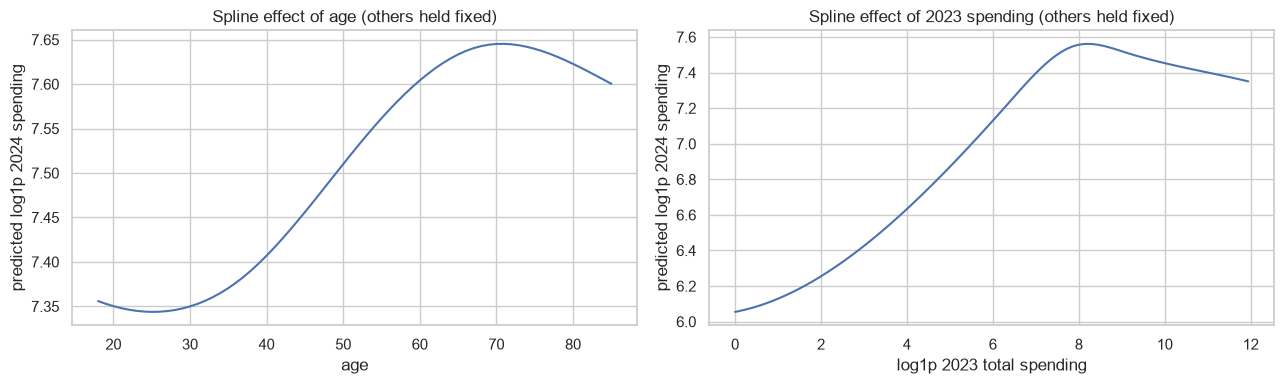

In [174]:
def make_spline_ridge(alpha, cols=all_predictors):
    log1p = FunctionTransformer(np.log1p, feature_names_out="one-to-one")
    rest = [c for c in cols if c not in ["age", "tot_exp_y1"]]
    parts = [
        ("age_spline", SplineTransformer(degree=3, n_knots=5, knots="quantile"), [c for c in ["age"] if c in cols]),
        ("spend_spline", make_pipeline(log1p, SplineTransformer(degree=3, n_knots=5, knots="quantile")),
                         [c for c in ["tot_exp_y1"] if c in cols]),
        ("rest", make_preprocessor(rest), rest),
    ]
    pre = ColumnTransformer([p for p in parts if p[2]], verbose_feature_names_out=False)
    return make_pipeline(pre, Ridge(alpha=alpha))

add_reg(cv_reg_scores(f"Ridge + splines on age & prior spending (alpha={alpha_ridge})",
                                 make_spline_ridge(alpha_ridge)))

#vary one input, hold everything else at a typical adult.
spline_fit = make_spline_ridge(alpha_ridge).fit(X_train, ylog_train)
typical = X_train.iloc[[0]].copy()
for c in all_predictors:
    typical[c] = X_train[c].median() if c in skewed + numeric + binary else X_train[c].mode()[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ages = np.arange(18, 86)
grid = pd.concat([typical] * len(ages), ignore_index=True).assign(age=ages)
axes[0].plot(ages, spline_fit.predict(grid))
axes[0].set(xlabel="age", ylabel="predicted log1p 2024 spending", title="Spline effect of age (others held fixed)")
spend = np.expm1(np.linspace(0, np.log1p(X_train["tot_exp_y1"].quantile(0.995)), 100))
grid = pd.concat([typical] * len(spend), ignore_index=True).assign(tot_exp_y1=spend)
axes[1].plot(np.log1p(spend), spline_fit.predict(grid))
axes[1].set(xlabel="log1p 2023 total spending", ylabel="predicted log1p 2024 spending",
            title="Spline effect of 2023 spending (others held fixed)")
plt.tight_layout()
plt.show()

**Notes** 
* The age predicted spending is flat from 18 to about 30, rises steadily to a peak around 70, then dips slightly.
* The curve for 2023 spending rises to about $3,000 (log1p of about 8), then levels off and declines a little. Prior-use information (Rx, office visits) is held fixed in this plot, so a higher total past that point mostly means more one-time spending (like going to the hospital/ER), which doesn't recur. 
* Still, the spline model's CV R² is slightly lower than ridge. 

**9. Attempting a Two-Part Model**

13.6% of adults spent $0 in 2024, so one straight line has trouble fitting a spike at zero and the continuous spread above it. I wanted to try making a two-part model that combines logistic regression for P(any spending in 2024) and ridge regression for log(spending among people who spent something). I got this idea for another person who used this dataset for a GitHub repository (check sources below), but their two-part model was a combination of logistic regression and Gamma GLM. 

Because log1p($0) = 0, the prediction on our log scale is P(any) × predicted log spending if any.

In [175]:
class TwoPartModel(RegressorMixin, BaseEstimator):
    #logistic regression for P(spending > 0) and ridge on log1p(spending) for spenders.
    #prediction on the log1p scale: P(spending > 0) * E[log1p(spending) | spending > 0]
    def __init__(self, cols, C=1.0, alpha=1.0):
        self.cols = cols
        self.C = C
        self.alpha = alpha

    def fit(self, X, y):
        y = np.asarray(y)
        spent = y > 0
        self.part1_ = make_pipeline(make_preprocessor(self.cols),
                                    LogisticRegression(C=self.C, max_iter=5000)).fit(X, spent.astype(int))
        self.part2_ = make_pipeline(make_preprocessor(self.cols), Ridge(alpha=self.alpha)).fit(X[spent], y[spent])
        return self

    def predict(self, X):
        return self.part1_.predict_proba(X)[:, 1] * self.part2_.predict(X)

add_reg(cv_reg_scores(f"Two-part model (logistic C=1 + ridge alpha={alpha_ridge})",
                                 TwoPartModel(all_predictors, C=1.0, alpha=alpha_ridge)))

any_train = (ydol_train > 0).astype(int)
p_any = cross_val_predict(make_pipeline(make_preprocessor(all_predictors), LogisticRegression(C=1.0, max_iter=5000)),
                          X_train, any_train, cv=cv_clf, method="predict_proba", n_jobs=-1)[:, 1]
print(f"Logistic Regression Alone: out-of-fold AUC for 'any 2024 spending' = {roc_auc_score(any_train, p_any):.3f}; "
      f"Average P(any) for adults who actually spent $0 = {p_any[any_train.to_numpy() == 0].mean():.2f}")
reg_table_now().round(3)

Logistic Regression Alone: out-of-fold AUC for 'any 2024 spending' = 0.908; Average P(any) for adults who actually spent $0 = 0.52


,CV RMSE,RMSE sd,CV R2,R2 sd
model,,,,
Mean only,3.220,0.031,-0.000,0.000
Next year = last year (no fitting),2.548,NaN,0.374,NaN
Simple regression on log 2023 spending,2.410,0.046,0.440,0.018
"OLS, all blocks",2.209,0.038,0.529,0.014
Ridge (alpha=100.0),2.197,0.038,0.534,0.015
Lasso (alpha=0.01),2.196,0.038,0.535,0.015
Lasso one-SE (alpha=0.02),2.201,0.037,0.533,0.014
Elastic net (alpha=0.02),2.196,0.037,0.534,0.014
Ridge + splines on age & prior spending (alpha=100.0),2.212,0.039,0.528,0.015


**Notes**
* The two-part model performs about the same as ridge. The zeros are not unpredictable, since Logistic Regression on its own ranks who will spend anything quite well (out-of-fold AUC 0.91). But adults who actually spent $0 still get P(any) = 0.52 on average, so the combined prediction for them stays far from 0. A single linear model on log1p already captures this mixture about as well as the two-part model does.

**10. Gradient boosting**

* 'HistGradientBoostingRegressor' builds a long sequence of small trees, each one correcting the errors of the ones before it. Trees capture interactions and nonlinearity without being told to. This model tries a small grid of learning rates and tree sizes. Early stopping picks the number of trees using an internal 10% validation split.

In [176]:
def make_hgb(cols=all_predictors, learning_rate=0.05, max_leaf_nodes=15):
    return make_pipeline(make_preprocessor(cols),
                         HistGradientBoostingRegressor(learning_rate=learning_rate, max_leaf_nodes=max_leaf_nodes,
                                                       min_samples_leaf=40, l2_regularization=1.0, max_iter=500,
                                                       early_stopping=True, validation_fraction=0.1,
                                                       n_iter_no_change=20, random_state=random_seed))

hgb_rows = []
for lr in [0.03, 0.1]:
    for leaves in [7, 15, 31]:
        r = cv_reg_scores(f"hgb lr={lr} leaves={leaves}", make_hgb(learning_rate=lr, max_leaf_nodes=leaves))
        hgb_rows.append({"learning_rate": lr, "max_leaf_nodes": leaves, **{k: v for k, v in r.items() if k != "model"}})
hgb_results = pd.DataFrame(hgb_rows)
best_hgb = hgb_results.loc[hgb_results["CV RMSE"].idxmin()]
hgb_params = {"learning_rate": float(best_hgb["learning_rate"]), "max_leaf_nodes": int(best_hgb["max_leaf_nodes"])}
print("Best gradient boosting settings:", hgb_params)
add_reg(cv_reg_scores(f"Gradient boosting (lr={hgb_params['learning_rate']}, leaves={hgb_params['max_leaf_nodes']})",
                                 make_hgb(**hgb_params)))
hgb_results.round(4)

Best gradient boosting settings: {'learning_rate': 0.03, 'max_leaf_nodes': 15}


,learning_rate,max_leaf_nodes,CV RMSE,RMSE sd,CV R2,R2 sd
0,0.03,7,2.1917,0.0452,0.5364,0.0173
1,0.03,15,2.1897,0.0458,0.5373,0.0158
2,0.03,31,2.1978,0.0493,0.5338,0.0189
3,0.10,7,2.1929,0.0509,0.5359,0.0191
4,0.10,15,2.1939,0.0522,0.5354,0.0196
5,0.10,31,2.2044,0.0536,0.5310,0.0194


**11. Model Comparisons**

,CV RMSE,RMSE sd,CV R2,R2 sd
model,,,,
Mean only,3.220,0.031,-0.000,0.000
Next year = last year (no fitting),2.548,NaN,0.374,NaN
Simple regression on log 2023 spending,2.410,0.046,0.440,0.018
"OLS, all blocks",2.209,0.038,0.529,0.014
Ridge (alpha=100.0),2.197,0.038,0.534,0.015
Lasso (alpha=0.01),2.196,0.038,0.535,0.015
Lasso one-SE (alpha=0.02),2.201,0.037,0.533,0.014
Elastic net (alpha=0.02),2.196,0.037,0.534,0.014
Ridge + splines on age & prior spending (alpha=100.0),2.212,0.039,0.528,0.015


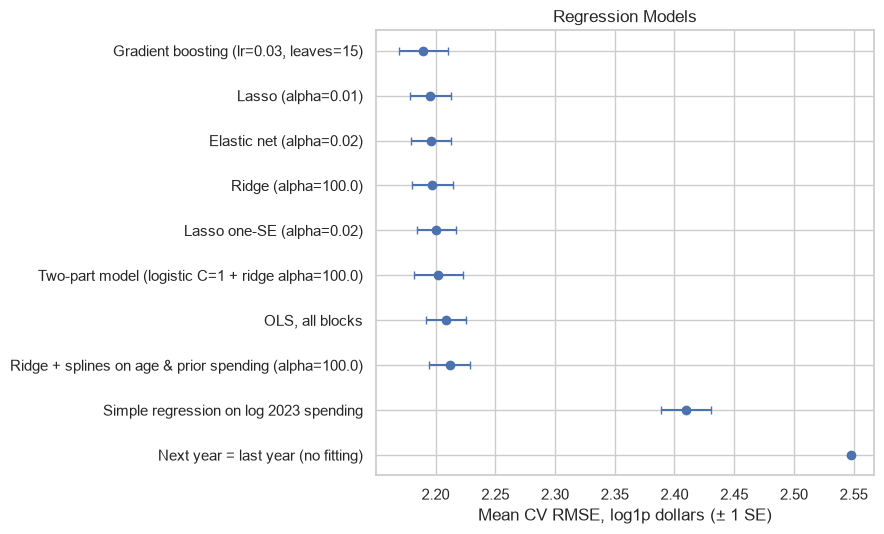

,R^2 gain vs ridge (mean),SD across folds
Mean only,-0.5341,0.0164
Simple regression on log 2023 spending,-0.0944,0.0216
"OLS, all blocks",-0.0049,0.0022
Ridge (alpha=100.0),0.0000,0.0000
Lasso (alpha=0.01),0.0007,0.0016
Lasso one-SE (alpha=0.02),-0.0014,0.0029
Elastic net (alpha=0.02),0.0005,0.0018
Ridge + splines on age & prior spending (alpha=100.0),-0.0061,0.0020
Two-part model (logistic C=1 + ridge alpha=100.0),-0.0021,0.0071
"Gradient boosting (lr=0.03, leaves=15)",0.0033,0.0060


In [177]:
reg_table = reg_table_now()
display(reg_table.round(3))

plot_df = reg_table.drop(index="Mean only").sort_values("CV RMSE", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.errorbar(plot_df["CV RMSE"], range(len(plot_df)), xerr=plot_df["RMSE sd"].fillna(0) / np.sqrt(5),
            fmt="o", capsize=3)
ax.set_yticks(range(len(plot_df)), plot_df.index)
ax.set(xlabel="Mean CV RMSE, log1p dollars (± 1 SE)", title="Regression Models")
plt.tight_layout()
plt.show()

#paired comparison vs. the best ridge using per-fold R^2 differences
ridge_name = f"Ridge (alpha={alpha_ridge})"
paired = pd.DataFrame({name: FOLD_R2[name] - FOLD_R2[ridge_name] for name in reg_table.index if name in FOLD_R2}).T
paired = pd.DataFrame({"R^2 gain vs ridge (mean)": paired.mean(axis=1), "SD across folds": paired.std(axis=1, ddof=1)})
paired.round(4)

In [178]:
#pick the final models for testing using CV only.
linear_family = [n for n in reg_table.index if n.startswith(("OLS", "Ridge", "Lasso", "Elastic", "Two-part"))]
best_linear = reg_table.loc[linear_family, "CV RMSE"].idxmin()
best_hgb = [n for n in reg_table.index if n.startswith("Gradient boosting")][0]
print("Best linear-family model by CV RMSE:", best_linear)
print("Tree model:", best_hgb)

#RMSE of ~2.2 log units mean for a typical adult
oof_ridge = cross_val_predict(make_linear("ridge", alpha_ridge), X_train, ylog_train, cv=cv_reg, n_jobs=-1)
abs_err = np.abs(ylog_train - oof_ridge)
print(f"\nRidge, out-of-fold: Median Absolute Error = {abs_err.median():.2f} log units "
      f"(a factor of {np.exp(abs_err.median()):.1f}); within 1 log unit: {(abs_err <= 1).mean():.0%}; "
      f"median error for adults with $0 in 2024 = {abs_err[ydol_train == 0].median():.2f}")

Best linear-family model by CV RMSE: Lasso (alpha=0.01)
Tree model: Gradient boosting (lr=0.03, leaves=15)

Ridge, out-of-fold: Median Absolute Error = 1.10 log units (a factor of 3.0); within 1 log unit: 46%; median error for adults with $0 in 2024 = 3.34


**Notes**
* Every model that uses all blocks lands within about 0.01 R² of the others. Gradient boosting has the best mean (R² 0.537), but its paired gain over Ridge (0.003) is half its fold-to-fold SD (0.006).
* A more flexible model doing no better than a linear one suggests that, once prior spending is in the model, the relationship is mostly additive and close to linear on the log scale. This is not true for every predictor set since without prior spending, boosting is still better.
* Based on the lowest mean CV RMSE, Lasso (alpha = 0.01) is carried to the final test as the best linear-family model, along with gradient boosting.
* Our RMSE of 2.2 log units is inflated by a minority of very large misses, mostly adults who spent $0 and adults predicted to spend almost nothing who then spent a few thousand dollars. The median out-of-fold miss is only 1.1 log units (a factor of about 3), and 46% of adults are predicted within 1 log unit (a factor of e = 2.7) of their actual spending. For adults who spent $0 in 2024, the median miss is 3.3 log units.

**12. Block Version Check**

* First we'll check one block alone to see how much each type of information predicts by itself. 
* Then we'll leave one block out to see how much does R² drop when one block is removed from the full model (Aka, what is it's unique information that no other block can stand in for?)
* Next, we'll add blocks one at a time, once with prior spending added right after demographics and once with prior spending held out until the end (This answers how well can we predict costs without prior spending data).
* The gain from adding a block depends on what's already in the model, so we can average each block's gain over every possible order of adding blocks. The six shares add up to the full model's R², which answers "how much does each type contribute?" 
* Lastly, we'll check if these conclusions survive some objections (overlapping blocks, timing of a few items, which part of demographics matters)?

We'll use 'RidgeCV' first because it retunes its penalty within every fit, which is fair to small and large block sets alike. Then we'll repeat checking one block alone and leaving one block out with gradient boosting as a nonlinear check.

In [179]:
ridge_alphas = np.logspace(-1, 4, 16)

def make_ridgecv(cols):
    return make_pipeline(make_preprocessor(cols), RidgeCV(alphas=ridge_alphas))

_version_cache = {}

def version_r2(cols, kind="ridge"):
    #per-fold CV R2 for one predictor set (cached, since the sharing step reuses many subsets)
    key = (kind, tuple(sorted(cols)))
    if key not in _version_cache:
        model = make_ridgecv(cols) if kind == "ridge" else make_hgb(cols, **hgb_params)
        _version_cache[key] = cross_validate(model, X_train[cols], ylog_train, cv=cv_reg, n_jobs=-1,
                                             scoring="r2")["test_score"]
    return _version_cache[key]

def cols_for(blocks):
    return [c for b in blocks for c in blocks[b]]

block_names = list(blocks)
no_prior = [b for b in block_names if b != "prior_use"]

start = time.perf_counter()
full_ridge = version_r2(all_predictors)
rows = []
for b in block_names:
    alone = version_r2(blocks[b])
    without = version_r2(cols_for({k: blocks[k] for k in block_names if k != b}))
    rows.append({"block": b, "R2 alone": alone.mean(), "R2 alone sd": alone.std(),
                 "R2 drop when removed": (full_ridge - without).mean(),
                 "drop sd (paired)": (full_ridge - without).std(ddof=1)})
alone_tbl = pd.DataFrame(rows).set_index("block")
print(f"Full model (all blocks), RidgeCV: CV R2 = {full_ridge.mean():.3f} (sd {full_ridge.std():.3f})")
print(f"2023 total spending alone, RidgeCV: CV R2 = {version_r2(['tot_exp_y1']).mean():.3f}")
print(f"({time.perf_counter() - start:.0f} s)")
alone_tbl.round(4)

Full model (all blocks), RidgeCV: CV R2 = 0.534 (sd 0.014)
2023 total spending alone, RidgeCV: CV R2 = 0.440
(7 s)


,R2 alone,R2 alone sd,R2 drop when removed,drop sd (paired)
block,,,,
demographics,0.2825,0.0199,0.0205,0.0095
prior_use,0.4974,0.0163,0.0962,0.0174
conditions,0.3063,0.0097,0.0003,0.0022
health_status,0.1253,0.0175,0.0010,0.0009
engagement,0.2593,0.0184,0.0024,0.0031
behavior,0.1029,0.0095,0.0009,0.0003


Prior spending added right after demographics


,added,CV R2,gain,gain sd (paired)
step,,,,
1,demographics,0.2825,0.2825,NaN
2,prior_use,0.5264,0.2438,0.0297
3,conditions,0.5279,0.0015,0.0024
4,health_status,0.5302,0.0023,0.0025
5,engagement,0.5329,0.0027,0.0035
6,behavior,0.5338,0.0009,0.0003


Prior spending held out until the last step


,added,CV R2,gain,gain sd (paired)
step,,,,
1,demographics,0.2825,0.2825,NaN
2,conditions,0.4071,0.1245,0.0105
3,health_status,0.4140,0.0069,0.0052
4,engagement,0.4369,0.0230,0.0073
5,behavior,0.4377,0.0007,0.0013
6,prior_use,0.5338,0.0962,0.0174


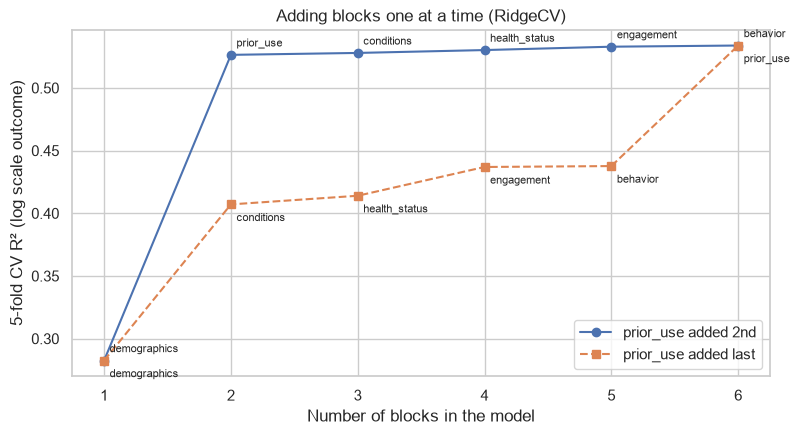

In [180]:
#third check
def build_up(order, kind="ridge"):
    rows, prev = [], np.zeros(5)
    for i in range(1, len(order) + 1):
        r2 = version_r2(cols_for(order[:i]), kind)
        rows.append({"step": i, "added": order[i - 1], "CV R2": r2.mean(), "gain": (r2 - prev).mean(),
                     "gain sd (paired)": (r2 - prev).std(ddof=1) if i > 1 else np.nan})
        prev = r2
    return pd.DataFrame(rows).set_index("step")

def cols_for(block_names):
    return [c for b in block_names for c in blocks[b]]
path_with = build_up(["demographics", "prior_use", "conditions", "health_status", "engagement", "behavior"])
path_without = build_up(["demographics", "conditions", "health_status", "engagement", "behavior", "prior_use"])
print("Prior spending added right after demographics")
display(path_with.round(4))
print("Prior spending held out until the last step")
display(path_without.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
for path, label, style, offset in [(path_with, "prior_use added 2nd", "o-", (4, 6)),
                                   (path_without, "prior_use added last", "s--", (4, -12))]:
    ax.plot(range(1, 7), path["CV R2"], style, label=label)
    for i, row in path.iterrows():
        ax.annotate(row["added"], (i, row["CV R2"]), textcoords="offset points", xytext=offset, fontsize=8)
ax.set(xlabel="Number of blocks in the model", ylabel="5-fold CV R² (log scale outcome)",
       title="Adding blocks one at a time (RidgeCV)")
ax.legend()
plt.show()

In [181]:
#Average gain from adding each block, over every order in which blocks could be added.
#needs CV R2 for every one of the 2^6 = 64 block subsets 
start = time.perf_counter()
value = {(): 0.0}   #the empty model predicts the mean, R2 = 0
for k in range(1, len(block_names) + 1):
    for subset in combinations(block_names, k):
        value[subset] = version_r2(cols_for(subset)).mean()

n = len(block_names)
Share = {}
for b in block_names:
    others = [x for x in block_names if x != b]
    total = 0.0
    for k in range(len(others) + 1):
        for S in combinations(others, k):
            with_b = tuple(x for x in block_names if x in S or x == b)
            weight = factorial(k) * factorial(n - k - 1) / factorial(n)
            total += weight * (value[with_b] - value[S])
    Share[b] = total
Share = pd.Series(Share, name="Share R2")
print(f"Share sum to {Share.sum():.3f} (= full-model CV R2 {value[tuple(block_names)]:.3f})  [{time.perf_counter() - start:.0f} s]")
(Share.to_frame().assign(percent_of_full=lambda d: (100 * d["Share R2"] / d["Share R2"].sum()).round(1))
 .sort_values("Share R2", ascending=False).round(4))

Share sum to 0.534 (= full-model CV R2 0.534)  [21 s]


,Share R2,percent_of_full
prior_use,0.2252,42.2
demographics,0.0968,18.1
conditions,0.0888,16.6
engagement,0.0714,13.4
health_status,0.0297,5.6
behavior,0.0218,4.1


In [182]:
#the same "alone" and "leave one out" comparisons with gradient boosting (this is a nonlinear check)
start = time.perf_counter()
full_hgb = version_r2(all_predictors, "hgb")
rows = []
for b in block_names:
    alone = version_r2(blocks[b], "hgb")
    without = version_r2(cols_for([x for x in block_names if x != b]), "hgb")
    rows.append({"block": b, "R2 alone": alone.mean(), "R2 drop when removed": (full_hgb - without).mean(),
                 "drop sd (paired)": (full_hgb - without).std(ddof=1)})
alone_hgb = pd.DataFrame(rows).set_index("block")
print(f"Full model, gradient boosting: CV R2 = {full_hgb.mean():.3f}   [{time.perf_counter() - start:.0f} s]")
alone_hgb.round(4)

Full model, gradient boosting: CV R2 = 0.537   [25 s]


,R2 alone,R2 drop when removed,drop sd (paired)
block,,,
demographics,0.2944,0.0192,0.0085
prior_use,0.4997,0.0472,0.0091
conditions,0.4239,0.0053,0.0082
health_status,0.1611,-0.0001,0.0033
engagement,0.2627,0.0010,0.0013
behavior,0.1021,-0.0022,0.0015


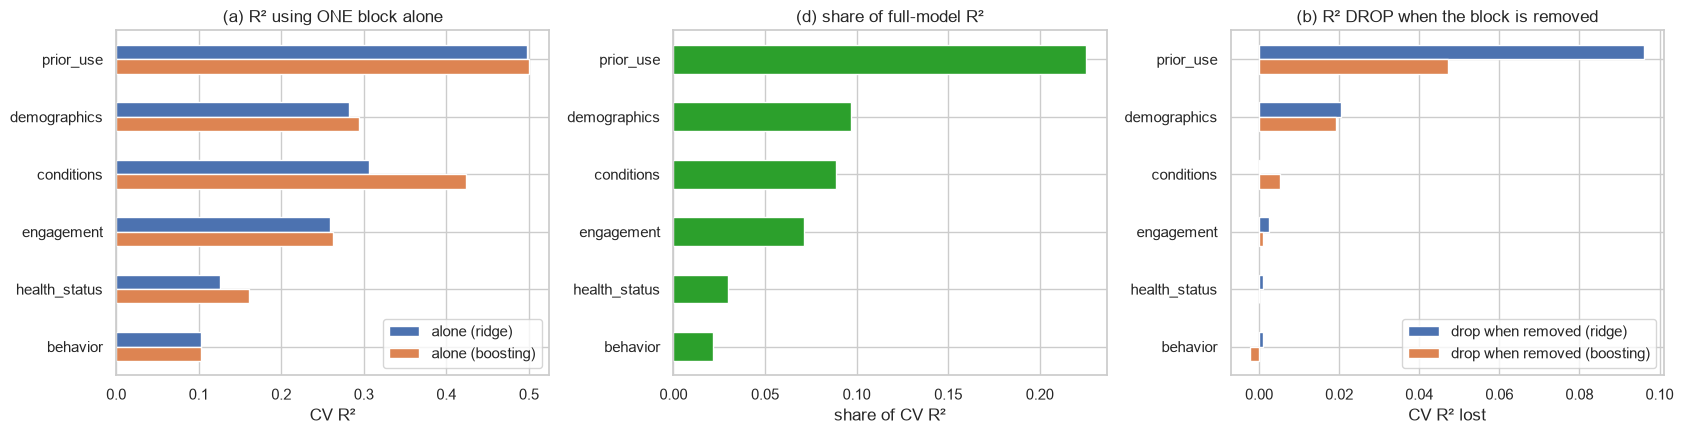

,alone (ridge),alone (boosting),share (ridge),drop when removed (ridge),drop when removed (boosting)
prior_use,0.4974,0.4997,0.2252,0.0962,0.0472
demographics,0.2825,0.2944,0.0968,0.0205,0.0192
conditions,0.3063,0.4239,0.0888,0.0003,0.0053
engagement,0.2593,0.2627,0.0714,0.0024,0.0010
health_status,0.1253,0.1611,0.0297,0.0010,-0.0001
behavior,0.1029,0.1021,0.0218,0.0009,-0.0022


In [183]:
#block results
summary_blocks = pd.DataFrame({
    "alone (ridge)": alone_tbl["R2 alone"],
    "alone (boosting)": alone_hgb["R2 alone"],
    "share (ridge)": Share,
    "drop when removed (ridge)": alone_tbl["R2 drop when removed"],
    "drop when removed (boosting)": alone_hgb["R2 drop when removed"],
}).sort_values("share (ridge)", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
summary_blocks[["alone (ridge)", "alone (boosting)"]].plot.barh(ax=axes[0])
axes[0].set(title="(a) R² using ONE block alone", xlabel="CV R²")
summary_blocks[["share (ridge)"]].plot.barh(ax=axes[1], color="tab:green", legend=False)
axes[1].set(title="(d) share of full-model R²", xlabel="share of CV R²")
summary_blocks[["drop when removed (ridge)", "drop when removed (boosting)"]].plot.barh(ax=axes[2])
axes[2].set(title="(b) R² DROP when the block is removed", xlabel="CV R² lost")
for ax in axes:
    ax.invert_yaxis()
plt.tight_layout()
plt.show()
summary_blocks.round(4)

In [184]:
#a few extra versions of interest because I am a control freak
extra = {
    "ALL blocks": all_predictors,
    "ALL except prior_use (README challenge)": cols_for(no_prior),
    "ALL except prior_use and engagement": cols_for([b for b in no_prior if b != "engagement"]),
    "prior_use + demographics": cols_for(["demographics", "prior_use"]),
    "prior_use + demographics + conditions": cols_for(["demographics", "prior_use", "conditions"]),
    "2023 total spending only": ["tot_exp_y1"],
}
pd.DataFrame({name: {"ridge CV R2": version_r2(cols).mean(), "boosting CV R2": version_r2(cols, "hgb").mean()}
              for name, cols in extra.items()}).T.round(3)

,ridge CV R2,boosting CV R2
ALL blocks,0.534,0.537
ALL except prior_use (README challenge),0.438,0.490
ALL except prior_use and engagement,0.417,0.482
prior_use + demographics,0.526,0.527
prior_use + demographics + conditions,0.528,0.536
2023 total spending only,0.440,0.442


**FINAL NOTES**
* Prior spending and use is the most informative type by every measure. Alone it reaches CV R² of almost 0.50, close to the full model's 0.53. It has the largest share (0.225, or 42% of the full model's R²), and removing it costs the most (−0.096 R² for ridge, −0.047 for boosting).
* The other blocks predict reasonably well alone, but overlap heavily with prior use. Conditions alone reach R² 0.31 (0.42 with boosting), engagement 0.26, health status 0.13. Yet removing any one of them from the full model costs less than 0.003 R² (ridge). 
* Demographics carry the most unique information after prior use. Removing them costs about 0.02 R² for both models. The robustness checks below show that removing the four insurance variables costs about 0.006 R², while removing the other nine demographics (keeping insurance) costs about 0.010.
* Ridge reaches R² 0.44 and boosting 0.49, about 82% and 91% of the full model's R² respectively. Boosting does much better here. The robustness checks show that most of its performance comes from the conditions features. With those removed as well, boosting leads by only 0.010 (0.425 vs 0.415). 'n_conditions' shows the effect most clearly with a boosting score of 0.41 and ridge score of 0.28. 
* Engagement metrics are the second most informative type with 0.023 R² on top of demographics, conditions, and health status. But after adding prior use, it adds only 0.003. .
* Health status and behavior add little once conditions are known. Behavior's standalone R² (0.10) partly reflects SAQ completion since all three of its variables come from the SAQ, and their missing markers identify the adults who skipped the SAQ, who spend less.
* Conditions add 0.12 R² when they come before prior use but only 0.002 after it.

In [185]:
self_dx = [c for c in blocks["conditions"] if c.startswith("dx_")] + ["n_chronic"]       #asked of everyone
cond_features = [c for c in blocks["conditions"] if c not in self_dx]                        #n_conditions, n_cond_*, ccsr_*
SAQ_12M = ["office_visits_saq", "routine_checkup", "needed_specialist", "care_rating"]   #SAQ care items ("last 12 months")
insurance = ["insurance", "medicaid", "medicare", "uninsured_all_year"]
dollars_spend = [c for c in blocks["prior_use"] if c.endswith("_exp_y1")]
no_prior = cols_for(no_prior)

def drop(cols, remove):
    return [c for c in cols if c not in remove]

checks = {
    "All blocks (reference)": all_predictors,
    "All except prior use (reference)": no_prior,
    #conditions
    "Self-reported diagnoses only (dx_ + n_chronic)": self_dx,
    "Conditions features only": cond_features,
    "n_conditions only": ["n_conditions"],
    "All except prior use and conditions": drop(no_prior, cond_features),
    "All except prior use, conditions, and SAQ 12-month care items": drop(no_prior, cond_features + SAQ_12M),
    "All except the 2023 dollar amounts (keep counts)": drop(all_predictors, dollars_spend),
    #time related
    "All except SAQ 12-month care items": drop(all_predictors, SAQ_12M),
    "All except prior use and SAQ 12-month care items": drop(no_prior, SAQ_12M),
    "Engagement only, without SAQ 12-month care items": drop(blocks["engagement"], SAQ_12M),
    "All except self diagnosis and number of chronic conditions": drop(all_predictors, self_dx),
    "All except prior use, self diagnosis, and number of chronic conditions": drop(no_prior, self_dx),
    #demographics
    "All except the 4 insurance variables": drop(all_predictors, insurance),
    "All except the other 9 demographics": drop(all_predictors, drop(blocks["demographics"], insurance)),
}
start = time.perf_counter()
robust = pd.DataFrame({name: {"ridge CV R2": version_r2(cols).mean(), "boosting CV R2": version_r2(cols, "hgb").mean()}
                       for name, cols in checks.items()}).T

base = cols_for(["demographics", "conditions", "health_status"])
for label, eng in [("all engagement items", blocks["engagement"]),
                   ("without the SAQ 12-month care items", drop(blocks["engagement"], SAQ_12M))]:
    gain = (version_r2(base + eng) - version_r2(base)).mean()
    print(f"Ridge: engagement's gain on top of demographics + conditions + health_status ({label}): {gain:.4f}")
print(f"({time.perf_counter() - start:.0f} s)")
robust.round(3)

Ridge: engagement's gain on top of demographics + conditions + health_status (all engagement items): 0.0230
Ridge: engagement's gain on top of demographics + conditions + health_status (without the SAQ 12-month care items): 0.0105
(34 s)


,ridge CV R2,boosting CV R2
All blocks (reference),0.534,0.537
All except prior use (reference),0.438,0.490
Self-reported diagnoses only (dx_ + n_chronic),0.205,0.220
Conditions features only,0.288,0.412
n_conditions only,0.277,0.411
All except prior use and conditions,0.415,0.425
"All except prior use, conditions, and SAQ 12-month care items",0.395,0.404
All except the 2023 dollar amounts (keep counts),0.496,0.513
All except SAQ 12-month care items,0.532,0.538
All except prior use and SAQ 12-month care items,0.427,0.486


**Notes**
1. The condition features alone reach R² 0.29 (ridge) and 0.41 (boosting), and the number of conditions by itself gets almost all of that (0.28 / 0.41). Self diagnosis and number of chronic conditions, which everyone is asked, reach only 0.21 / 0.22. Removing the condition features as well as prior use drops R² to 0.415 (ridge) and 0.425 (boosting), about 78–79% of the full model, and boosting's advantage almost disappears. Removing the four SAQ care items too (they are partly self-reported use) leaves R² 0.395 (ridge) and 0.404 (boosting), about 74–75%. So with little or no information about 2023 use, is well below the 82–91% from simply dropping the prior-use block.
2. Dropping only the 2023 dollar amounts costs R² 0.496 (ridge) and 0.513 (boosting), still about 93–95% of the full model. Utilization counts (medical visits, prescription refills, etc) carry most of what the dollars tell us.
3. Without the four SAQ 12-month care items, the full model is unchanged (0.532 / 0.538), and the no-prior-spending model loses only 0.011 (ridge) / 0.004 (boosting). However, engagement alone falls from R² 0.26 to 0.13, and its gain in check 2 from 0.023 to 0.0105. About half of engagement's apparent value is self-reported use, and without those items it is roughly on par with health status (0.13). Dropping the self diagnosis and number of conditions changes the results by at most 0.004 R², so their possible 2024 overlap doesn't effect anything.
4. Removing the 4 insurance variables costs 0.006 (ridge) / 0.002 (boosting) R², and removing the other 9 demographics costs 0.010 / 0.011. Insurance has the largest lasso coefficient among the demographics, but it accounts for well under half of demographics' unique value. The rest is spread over the other demographic variables, and much of it is shared among them.
5. Our initial results regarding prior use hold under every check, but the ranking of diagnosed conditions and engagement comes show that much of the conditions block's value comes from event-linked condition counts, and much of engagement's comes from self-reported visit items. Both are partly indirect measures of 2023 use.

**13. Classification (Who will be a top-20% spender in 2024?)**

'high_cost_y2' = 1 for adults at or above the 80th percentile of 2024 spending (about $13,560). This part compares log loss and AUC across penalties with stratified 5-fold CV, then look at confusion matrices at two thresholds, ROC curves, and calibration.

In [186]:
base_rate = yhigh_train.mean()
ll_base = log_loss(yhigh_train, np.full(len(yhigh_train), base_rate))
print(f"Base rate: {base_rate:.3f}.  Base-rate log loss (training set): {ll_base:.4f}")

#high cost in 2023 vs mean high cost in 2024 (top 20% of 2023 spending, cutoff from training)
cut_2023 = X_train["tot_exp_y1"].quantile(0.8)
flag_2023 = (X_train["tot_exp_y1"] >= cut_2023).astype(int)
print(f"\n2023 top-20% flag (2023 spending >= ${cut_2023:,.0f}):")
print(f"  precision {precision_score(yhigh_train, flag_2023):.3f}, recall {recall_score(yhigh_train, flag_2023):.3f}, "
      f"accuracy {accuracy_score(yhigh_train, flag_2023):.3f}")

Base rate: 0.200.  Base-rate log loss (training set): 0.5005

2023 top-20% flag (2023 spending >= $12,009):
  precision 0.563, recall 0.563, accuracy 0.825


In [187]:
def make_logit(C=np.inf, l1_ratio=0, cols=all_predictors):
    #C = inverse penalty strength, l1_ratio 0 = ridge, 1 = lasso, C=np.inf = none.
    solver = "liblinear" if l1_ratio == 1 else "lbfgs"
    return Pipeline([("preprocess", make_preprocessor(cols)),
                     ("model", LogisticRegression(C=C, l1_ratio=l1_ratio, solver=solver, max_iter=5000,
                                                   random_state=random_seed))])

def cv_clf_scores(model, cols=all_predictors):
    res = cross_validate(model, X_train[cols], yhigh_train, cv=cv_clf, n_jobs=-1, scoring=["neg_log_loss", "roc_auc"])
    return {"log loss (mean)": -res["test_neg_log_loss"].mean(), "log loss (sd)": res["test_neg_log_loss"].std(),
            "AUC (mean)": res["test_roc_auc"].mean(), "AUC (sd)": res["test_roc_auc"].std()}

def cv_probs(model, cols=all_predictors):
    #out-of-fold predicted probabilities. each adult is scored by a model that did not see them
    return cross_val_predict(model, X_train[cols], yhigh_train, cv=cv_clf, method="predict_proba", n_jobs=-1)[:, 1]

def precision_recall_table(y_true, p, thresholds=(0.5, 0.2)):
    rows = []
    for t in thresholds:
        y_hat = (p >= t).astype(int)
        rows.append({"threshold": t, "precision": precision_score(y_true, y_hat, zero_division=0),
                     "recall": recall_score(y_true, y_hat), "flagged": int(y_hat.sum())})
    return pd.DataFrame(rows)

def plot_confusion(y_true, p, title, thresholds=(0.5, 0.2)):
    fig, axes = plt.subplots(1, len(thresholds), figsize=(5 * len(thresholds), 4))
    for ax, t in zip(axes, thresholds):
        ConfusionMatrixDisplay.from_predictions(y_true, (p >= t).astype(int), ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"{title}\nthreshold = {t}")
    plt.tight_layout()
    plt.show()

clf_results = {
    "Logistic, 2023 spending only": cv_clf_scores(make_logit(np.inf, 0, ["tot_exp_y1"]), ["tot_exp_y1"]),
    "Logistic, no penalty, all blocks": cv_clf_scores(make_logit(np.inf, 0)),
}
pd.DataFrame(clf_results).T.round(4)

,log loss (mean),log loss (sd),AUC (mean),AUC (sd)
"Logistic, 2023 spending only",0.3913,0.0044,0.8231,0.0054
"Logistic, no penalty, all blocks",0.3783,0.0170,0.8348,0.0104


Ridge and lasso logistic regression across C

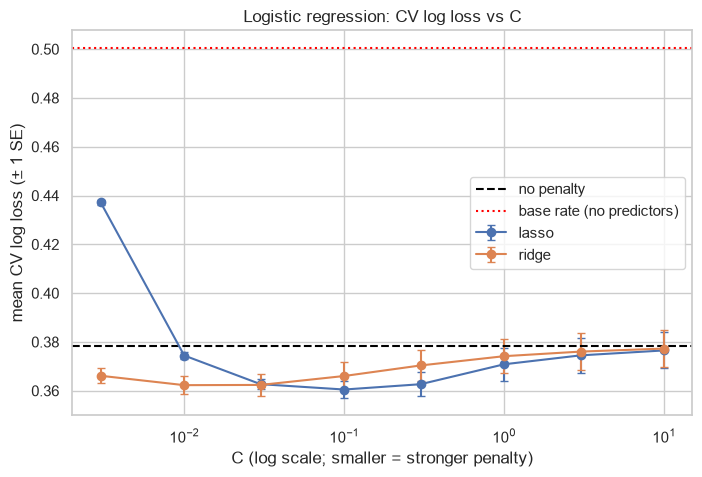

Best ridge C: 0.01 | best lasso C: 0.1


,penalty,C,log loss (mean),log loss (sd),AUC (mean),AUC (sd)
0,ridge,0.003,0.3661,0.0067,0.8439,0.0061
1,ridge,0.010,0.3623,0.0085,0.8464,0.0066
2,ridge,0.030,0.3624,0.0102,0.8461,0.0073
3,ridge,0.100,0.3660,0.0124,0.8430,0.0087
4,ridge,0.300,0.3704,0.0143,0.8398,0.0097
5,ridge,1.000,0.3742,0.0158,0.8371,0.0104
6,ridge,3.000,0.3760,0.0167,0.8360,0.0109
7,ridge,10.000,0.3773,0.0167,0.8352,0.0105
8,lasso,0.003,0.4372,0.0022,0.8195,0.0082
9,lasso,0.010,0.3744,0.0031,0.8436,0.0045


In [188]:
C_values = [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]
rows = []
for penalty, l1 in [("ridge", 0), ("lasso", 1)]:
    for C in C_values:
        rows.append({"penalty": penalty, "C": C, **cv_clf_scores(make_logit(C, l1))})
logit_grid = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 5))
for penalty, g in logit_grid.groupby("penalty"):
    ax.errorbar(g["C"], g["log loss (mean)"], yerr=g["log loss (sd)"] / np.sqrt(5), marker="o", capsize=3, label=penalty)
ax.axhline(clf_results["Logistic, no penalty, all blocks"]["log loss (mean)"], color="black", ls="--", label="no penalty")
ax.axhline(ll_base, color="red", ls=":", label="base rate (no predictors)")
ax.set(xscale="log", xlabel="C (log scale; smaller = stronger penalty)", ylabel="mean CV log loss (± 1 SE)",
       title="Logistic regression: CV log loss vs C")
ax.legend()
plt.show()

best_c = logit_grid.loc[logit_grid.groupby("penalty")["log loss (mean)"].idxmin()].set_index("penalty")
C_ridge, C_lasso = best_c.loc["ridge", "C"], best_c.loc["lasso", "C"]
print(f"Best ridge C: {C_ridge} | best lasso C: {C_lasso}")
clf_results[f"Ridge Logistic Regression (C={C_ridge})"] = cv_clf_scores(make_logit(C_ridge, 0))
clf_results[f"Lasso Logistic Regression (C={C_lasso})"] = cv_clf_scores(make_logit(C_lasso, 1))
logit_grid.round(4)

KNN votes among the k nearest training adults. It has no coefficients, so it is just a check on whether a linear boundary is good enough. Since we have 172 columns with varying types, the distances are cursed with dimensionality, so I don't expect this to reveal anything crazy.

In [189]:
def make_knn(k, cols=all_predictors):
    return Pipeline([("preprocess", make_preprocessor(cols)), ("model", KNeighborsClassifier(n_neighbors=k))])

knn_results = pd.DataFrame([{"k": k, **cv_clf_scores(make_knn(k))} for k in [25, 51, 101, 151, 201, 301, 401]])
k_best = int(knn_results.loc[knn_results["log loss (mean)"].idxmin(), "k"])
print(f"Best k (lowest CV log loss): {k_best}")
clf_results[f"KNN (k={k_best})"] = cv_clf_scores(make_knn(k_best))

def make_hgb_clf(cols=all_predictors):
    return Pipeline([("preprocess", make_preprocessor(cols)),
                     ("model", HistGradientBoostingClassifier(learning_rate=hgb_params["learning_rate"],
                                                              max_leaf_nodes=hgb_params["max_leaf_nodes"],
                                                              min_samples_leaf=40, l2_regularization=1.0, max_iter=500,
                                                              early_stopping=True, validation_fraction=0.1,
                                                              n_iter_no_change=20, random_state=random_seed))])

clf_results["Gradient boosting classifier"] = cv_clf_scores(make_hgb_clf())
knn_results.round(4)

Best k (lowest CV log loss): 401


,k,log loss (mean),log loss (sd),AUC (mean),AUC (sd)
0,25,0.6485,0.1176,0.8124,0.0098
1,51,0.5011,0.0379,0.8228,0.0049
2,101,0.4417,0.0283,0.8294,0.0027
3,151,0.4168,0.0157,0.8313,0.0035
4,201,0.4192,0.0143,0.8329,0.0042
5,301,0.4185,0.0102,0.8330,0.0054
6,401,0.4163,0.0042,0.8339,0.0062


In [190]:
clf_table = pd.DataFrame(clf_results).T
clf_table.loc["Base rate (no predictors)", ["log loss (mean)", "AUC (mean)"]] = [ll_base, 0.5]
clf_table = clf_table.sort_values("log loss (mean)")
clf_table.round(4)

,log loss (mean),log loss (sd),AUC (mean),AUC (sd)
Gradient boosting classifier,0.3515,0.0088,0.8547,0.0055
Lasso Logistic Regression (C=0.1),0.3605,0.0077,0.8481,0.0059
Ridge Logistic Regression (C=0.01),0.3623,0.0085,0.8464,0.0066
"Logistic, no penalty, all blocks",0.3783,0.0170,0.8348,0.0104
"Logistic, 2023 spending only",0.3913,0.0044,0.8231,0.0054
KNN (k=401),0.4163,0.0042,0.8339,0.0062
Base rate (no predictors),0.5005,NaN,0.5000,NaN


Mean Predicted Probability: Lasso 0.202 | Gradient Boosting 0.199 | KNN 0.115 | Actual High-Cost Rate 0.200


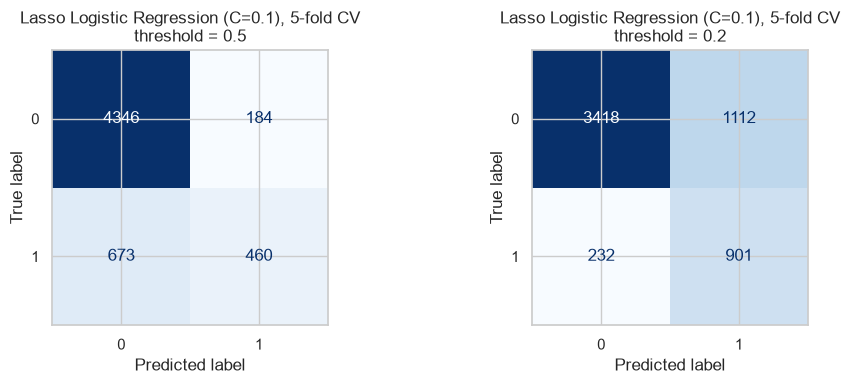

,threshold,precision,recall,flagged
0,0.5,0.714,0.406,644
1,0.2,0.448,0.795,2013


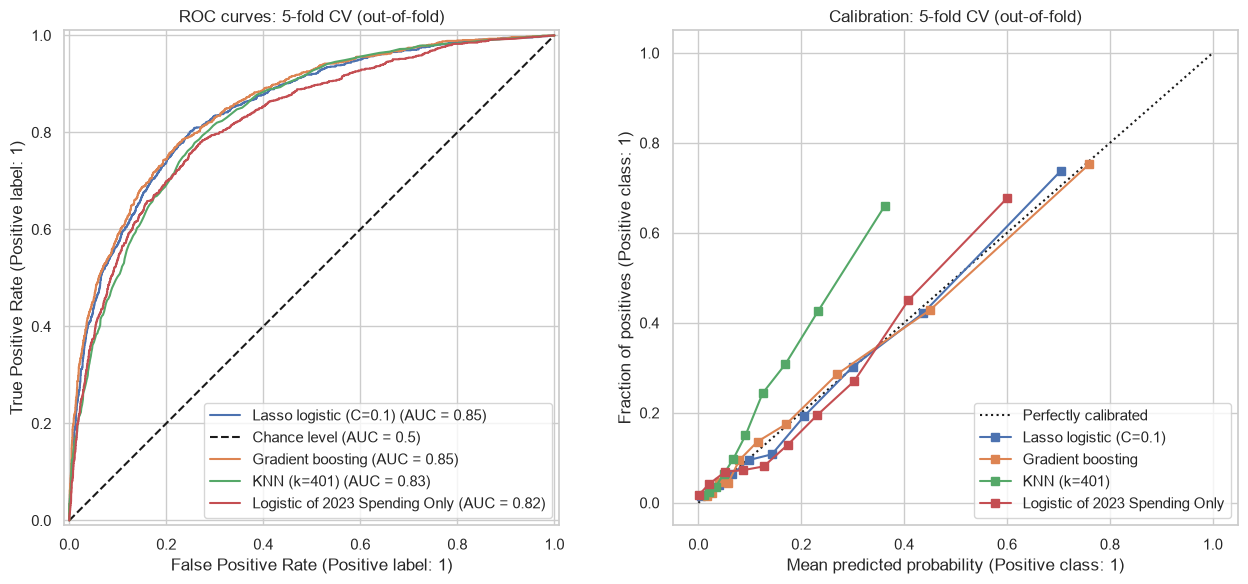

In [191]:
#out-of-fold predictions for confusion matrices, ROC curves, and class
p_lasso = cv_probs(make_logit(C_lasso, 1))
p_hgb = cv_probs(make_hgb_clf())
p_knn = cv_probs(make_knn(k_best))
p_prior = cv_probs(make_logit(np.inf, 0, ["tot_exp_y1"]), ["tot_exp_y1"])
print(f"Mean Predicted Probability: Lasso {p_lasso.mean():.3f} | Gradient Boosting {p_hgb.mean():.3f} | KNN {p_knn.mean():.3f} "
      f"| Actual High-Cost Rate {yhigh_train.mean():.3f}")

plot_confusion(yhigh_train, p_lasso, f"Lasso Logistic Regression (C={C_lasso}), 5-fold CV")
display(precision_recall_table(yhigh_train, p_lasso).round(3))

probs = {f"Lasso logistic (C={C_lasso})": p_lasso, "Gradient boosting": p_hgb, f"KNN (k={k_best})": p_knn,
         "Logistic of 2023 Spending Only": p_prior}
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for i, (name, p) in enumerate(probs.items()):
    RocCurveDisplay.from_predictions(yhigh_train, p, name=name, ax=axes[0], plot_chance_level=(i == 0))
    CalibrationDisplay.from_predictions(yhigh_train, p, n_bins=10, strategy="quantile", name=name, ax=axes[1])
axes[0].set_title("ROC curves: 5-fold CV (out-of-fold)")
axes[1].set_title("Calibration: 5-fold CV (out-of-fold)")
plt.tight_layout()
plt.show()

In [192]:
#odds from the lasso logistic model fit on the full training set
lasso_logit = make_logit(C_lasso, 1).fit(X_train, yhigh_train)
or_table = pd.DataFrame({"coef": lasso_logit.named_steps["model"].coef_[0]},
                        index=lasso_logit.named_steps["preprocess"].get_feature_names_out())
or_table["block"] = [feature_block(f) for f in or_table.index]
or_table["odds_ratio"] = np.exp(or_table["coef"])
print(f"Lasso logistic keeps {(or_table['coef'] != 0).sum()} of {len(or_table)} model columns")
display(or_table.assign(kept=or_table["coef"] != 0).groupby("block")["kept"].agg(["size", "sum"])
        .rename(columns={"size": "columns", "sum": "kept"}))
or_table[or_table["coef"] != 0].sort_values("coef", key=abs, ascending=False).head(15).round(3)

Lasso logistic keeps 54 of 172 model columns


,columns,kept
block,,
behavior,12,1
conditions,85,25
demographics,31,10
engagement,14,1
health_status,16,7
prior_use,14,10


,coef,block,odds_ratio
tot_exp_y1,0.717,prior_use,2.049
rx_exp_y1,0.665,prior_use,1.944
ob_visits_y1,0.283,prior_use,1.328
n_chronic,0.237,conditions,1.267
rx_fills_y1,-0.220,prior_use,0.802
dx_chol,-0.196,conditions,0.822
any_limitation,0.145,health_status,1.156
hh_days_y1,0.128,prior_use,1.136
ccsr_END005,0.127,conditions,1.135
op_visits_y1,0.126,prior_use,1.134


**Notes**
* Every model beats the base rate (log loss 0.50) by a wide margin. Last year's spending got AUC 0.82.
* Gradient boosting has the best CV log loss (0.3515) and AUC (0.855), followed closely by lasso logistic (0.3605 / 0.848) and ridge logistic. Unpenalized logistic is worse, because rare 0/1 flags let it overfit.
* KNN is the weakest probability model even at its best k (k = 4010). Its CV log loss is flat at about 0.42 from k = 150 onward, so a larger k wouldn't help. Its AUC is comparable with other models, but its calibration curve sits above the diagonal in every bin. Its average predicted probability is 0.115 against an actual rate of 0.200, so it systematically underpredicts risk. High-cost adults tend to sit in sparse parts of the feature space, so most of their nearest neighbors are lower-cost adults.
* Lasso logistic and gradient boosting both track the diagonal closely, and their average predicted probabilities (0.202 and 0.199) match the actual rate.
* Our thresholds (from Lasso pooled out-of-fold) is that at 0.5, the model flags 644 training adults. 71% of them really are high-cost, but it catches only 41% of the high-cost group. At 0.2 (the base rate) it catches 80% of them, and 45% of those flagged are actually high-cost. The "top 20% in 2023" rule has precision and recall of 0.56. Just over half of last year's top spenders are in the top 20% again.
* Lasso logistic keeps 54 of 172 columns, and 25 of them are from the conditions block. The odds ratios are per 1 SD for numeric predictors. 1 SD of log 2023 spending multiplies the odds of being high-cost by about 2.0, Rx spending by 1.9, office visits by 1.3, and number of chronic conditions by 1.3. However, these columns overlap with Rx spending and the condition counts. Also, 'ccsr_END002'/'ccsr_END005' and 'ccsr_DEN001'/ccsr_DEN002' are similar variables, so Lasso's split of weight between them is arbitrary.

In [193]:
#the same "alone" and "leave one out" comparisons, now with ridge logistic regression using the C and CV AUC as the score.

def clf_version(cols):
    return cross_validate(make_logit(C_ridge, 0, cols), X_train[cols], yhigh_train, cv=cv_clf, n_jobs=-1,
                          scoring=["roc_auc", "neg_log_loss"])

full_clf = clf_version(all_predictors)
rows = []
for b in block_names:
    alone = clf_version(blocks[b])
    without = clf_version(cols_for([x for x in block_names if x != b]))
    rows.append({"block": b, "AUC Alone": alone["test_roc_auc"].mean(),
                 "AUC drop when removed": (full_clf["test_roc_auc"] - without["test_roc_auc"]).mean(),
                 "Drop SD (paired)": (full_clf["test_roc_auc"] - without["test_roc_auc"]).std(ddof=1)})
clf_blocks = pd.DataFrame(rows).set_index("block").sort_values("AUC Alone", ascending=False)
no_prior_clf = clf_version(no_prior)
print(f"All blocks: CV AUC {full_clf['test_roc_auc'].mean():.3f} | "
      f"All except prior use: CV AUC {no_prior_clf['test_roc_auc'].mean():.3f}")
print(f"Inside the conditions block: self-reported diagnosis and number of conditions alone: CV AUC {clf_version(self_dx)['test_roc_auc'].mean():.3f} | "
      f"Number of conditions alone: CV AUC {clf_version(['n_conditions'])['test_roc_auc'].mean():.3f}")
clf_blocks.round(4)

All blocks: CV AUC 0.846 | All except prior use: CV AUC 0.821
Inside the conditions block: self-reported diagnosis and number of conditions alone: CV AUC 0.750 | Number of conditions alone: CV AUC 0.798


,AUC Alone,AUC drop when removed,Drop SD (paired)
block,,,
prior_use,0.8414,0.0252,0.0020
conditions,0.8117,0.0006,0.0023
health_status,0.7294,0.0007,0.0013
engagement,0.7162,-0.0010,0.0006
demographics,0.7142,0.0009,0.0008
behavior,0.6467,0.0005,0.0003


**Notes**
* Prior use alone (AUC 0.84) is almost as strong as all blocks together (0.846). Removing it costs 0.025 AUC, while removing any other block costs at most 0.001.
* Conditions are a strong second for classification (AUC 0.81 alone, ahead of health status 0.73, engagement 0.72, and demographics 0.71). But as in regression, most of that comes from 'n_conditions' (AUC 0.80 alone). Diagnosis variables and number of chronic conditions reach 0.75.
* Without prior spending, the logistic model still reaches CV AUC 0.82, compared to 0.85 including everything.

**14. Final holdout test (run once)**

expm1(predicted log) estimates something like the median dollar amount, not the mean, so it underestimates dollars. The recommended solution is usually to multiply every prediction by one factor, the average of e^residual, but that only works if the errors have the same spread for everyone. Here, adults predicted to spend little have much wider errors, so a single factor inflates everyone's prediction (the output below shows how large it gets). Therefore, we should split the training adults into 10 groups by their out-of-fold predicted log spending, and within each group scale exp(prediction) so the group's average matches its actual average spending.

In [194]:
def dollar_calibration(model, cols, n_groups=10):
    #learned from out-of-fold predictions on the training set only
    oof = cross_val_predict(model, X_train[cols], ylog_train, cv=cv_reg, n_jobs=-1)
    edges = np.quantile(oof, np.linspace(0, 1, n_groups + 1)[1:-1])
    group = np.digitize(oof, edges)
    actual_plus_1 = ydol_train.to_numpy() + 1
    factors = np.array([actual_plus_1[group == g].mean() / np.exp(oof[group == g]).mean() for g in range(n_groups)])
    one_factor = np.mean(np.exp(ylog_train.to_numpy() - oof))   #single-factor for comparison
    return edges, factors, one_factor

def to_dollars(pred_log, edges, factors):
    return np.clip(np.exp(pred_log) * factors[np.digitize(pred_log, edges)] - 1, 0, None)

no_prior_cols = cols_for([b for b in block_names if b != "prior_use"])
best_linear_builder = {
    "OLS": lambda cols: make_pipeline(make_preprocessor(cols), LinearRegression()),
    "Ridge + splines": lambda cols: make_spline_ridge(alpha_ridge, cols),
    "Ridge": lambda cols: make_linear("ridge", alpha_ridge, cols),
    "Lasso one-SE": lambda cols: make_linear("lasso", alpha_lasso_1se, cols),
    "Lasso": lambda cols: make_linear("lasso", alpha_lasso, cols),
    "Elastic": lambda cols: make_linear("elastic net", alpha_enet, cols),
    "Two-part": lambda cols: TwoPartModel(cols, C=1.0, alpha=alpha_ridge),
}
builder = next(f for key, f in best_linear_builder.items() if best_linear.startswith(key))

final_reg = {
    "Simple regression on log 2023 spending": (make_pipeline(make_preprocessor(["tot_exp_y1"]), LinearRegression()), ["tot_exp_y1"]),
    f"{best_linear}": (builder(all_predictors), all_predictors),
    f"{best_linear.split(' (')[0]}, ALL except prior_use": (builder(no_prior_cols), no_prior_cols),
    "Gradient boosting, all blocks": (make_hgb(all_predictors, **hgb_params), all_predictors),
    "Gradient boosting, ALL except prior use": (make_hgb(no_prior_cols, **hgb_params), no_prior_cols),
}

test_rows, fitted_final, test_pred_dollars = [], {}, {}
persist_test = np.log1p(X_test["tot_exp_y1"])
test_rows.append({"model": "Next year = last year (no fitting)",
                  "Test RMSE (log)": root_mean_squared_error(ylog_test, persist_test),
                  "Test R2 (log)": r2_score(ylog_test, persist_test),
                  "Test MAE ($)": mean_absolute_error(ydol_test, X_test["tot_exp_y1"]),
                  "Test R2 ($)": r2_score(ydol_test, X_test["tot_exp_y1"]),
                  "mean predicted / mean actual": X_test["tot_exp_y1"].mean() / ydol_test.mean()})
test_pred_dollars["Next year = last year (no fitting)"] = X_test["tot_exp_y1"].to_numpy()

for name, (model, cols) in final_reg.items():
    model.fit(X_train[cols], ylog_train)
    pred = model.predict(X_test[cols])
    edges, factors, one_factor = dollar_calibration(model, cols)
    if name == best_linear:
        print(f"{name}: single factor = {one_factor:.1f}; group-wise factors (low to high predicted spending) = "
              f"{np.round(factors, 1).tolist()}")
    dollars = to_dollars(pred, edges, factors)
    fitted_final[name] = (model, cols)
    test_pred_dollars[name] = dollars
    test_rows.append({"model": name, "Test RMSE (log)": root_mean_squared_error(ylog_test, pred),
                      "Test R2 (log)": r2_score(ylog_test, pred),
                      "Test MAE ($)": mean_absolute_error(ydol_test, dollars), "Test R2 ($)": r2_score(ydol_test, dollars),
                      "mean predicted / mean actual": dollars.mean() / ydol_test.mean()})

#a model fit directly on raw dollars for comparison on the dollar scale
raw_dollar = make_ridgecv(all_predictors).fit(X_train, ydol_train)
raw_pred = np.clip(raw_dollar.predict(X_test), 0, None)   #a linear model can predict negative dollars so we set min $0
test_pred_dollars["RidgeCV on raw dollars, all blocks"] = raw_pred
test_rows.append({"model": "RidgeCV on raw dollars, all blocks", "Test RMSE (log)": np.nan, "Test R2 (log)": np.nan,
                  "Test MAE ($)": mean_absolute_error(ydol_test, raw_pred), "Test R2 ($)": r2_score(ydol_test, raw_pred),
                  "mean predicted / mean actual": raw_pred.mean() / ydol_test.mean()})

raw_cv = cross_validate(make_ridgecv(all_predictors), X_train, ydol_train, cv=cv_reg, n_jobs=-1, scoring="r2")["test_score"]
print(f"RidgeCV on raw dollars: 5-fold CV dollar R2 on the training set = {raw_cv.mean():.3f} (folds {raw_cv.min():.2f} to {raw_cv.max():.2f})")
sq = (ydol_test - ydol_test.mean()) ** 2
print(f"The 5 largest of {len(ydol_test):,} test bills make up {sq.nlargest(5).sum() / sq.sum():.0%} of the dollar-scale "
      f"total sum of squares.")

test_table = pd.DataFrame(test_rows).set_index("model")
test_table.round(3)

Lasso (alpha=0.01): single factor = 20.5; group-wise factors (low to high predicted spending) = [85.7, 13.8, 9.4, 6.5, 4.2, 3.4, 2.7, 2.1, 1.7, 1.0]
RidgeCV on raw dollars: 5-fold CV dollar R2 on the training set = 0.161 (folds 0.07 to 0.21)
The 5 largest of 1,416 test bills make up 37% of the dollar-scale total sum of squares.


,Test RMSE (log),Test R2 (log),Test MAE ($),Test R2 ($),mean predicted / mean actual
model,,,,,
Next year = last year (no fitting),2.650,0.365,10562.278,0.097,0.936
Simple regression on log 2023 spending,2.487,0.441,10550.661,0.230,1.013
Lasso (alpha=0.01),2.278,0.531,10324.340,0.187,0.969
"Lasso, ALL except prior_use",2.512,0.429,11733.610,-0.043,0.899
"Gradient boosting, all blocks",2.258,0.539,9791.636,0.282,0.975
"Gradient boosting, ALL except prior use",2.356,0.498,10828.072,0.150,0.950
"RidgeCV on raw dollars, all blocks",NaN,NaN,10739.239,0.204,1.005


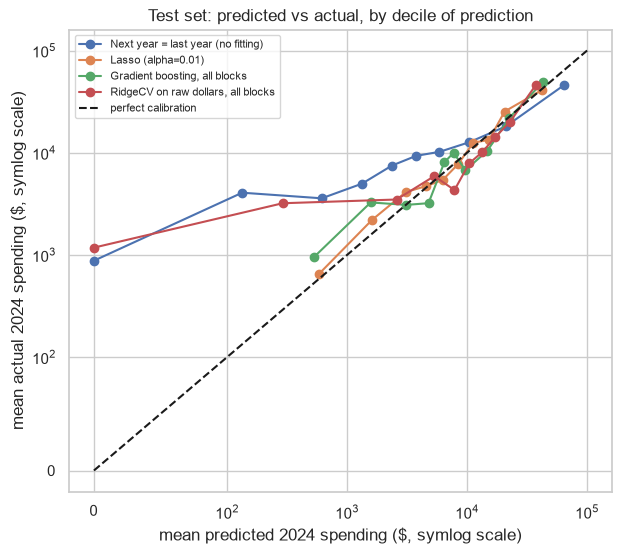

In [195]:
#sort test adults into 10 groups by predicted spending and compare mean predicted with actual
fig, ax = plt.subplots(figsize=(7, 6))
for name in ["Next year = last year (no fitting)", best_linear, "Gradient boosting, all blocks", "RidgeCV on raw dollars, all blocks"]:
    d = pd.DataFrame({"pred": test_pred_dollars[name], "actual": ydol_test.to_numpy()})
    d["decile"] = pd.qcut(d["pred"].rank(method="first"), 10, labels=False)
    g = d.groupby("decile")[["pred", "actual"]].mean()
    ax.plot(g["pred"], g["actual"], "o-", label=name)
lims = [0, 1e5]
ax.plot(lims, lims, "k--", label="perfect calibration")
ax.set_xscale("symlog", linthresh=100)   #symmetric log scale
ax.set_yscale("symlog", linthresh=100)
ax.set(xlabel="mean predicted 2024 spending ($, symlog scale)", ylabel="mean actual 2024 spending ($, symlog scale)",
       title="Test set: predicted vs actual, by decile of prediction")
ax.legend(fontsize=8)
plt.show()

,Test log loss,Test AUC,precision @0.2,recall @0.2,Recall @0.2,Precision @0.2
model,,,,,,
Base rate (no predictors),0.500,0.500,NaN,NaN,NaN,NaN
2023 top-20% flag (no fitting),NaN,0.731,0.528,NaN,0.594,NaN
"Logistic, 2023 spending only",0.397,0.812,NaN,NaN,0.792,0.378
"Lasso logistic (C=0.1), all blocks",0.356,0.847,NaN,NaN,0.799,0.431
"Lasso logistic (C=0.1), ALL except prior_use",0.379,0.826,NaN,NaN,0.753,0.431
"Gradient boosting classifier, all blocks",0.358,0.839,NaN,NaN,0.739,0.445


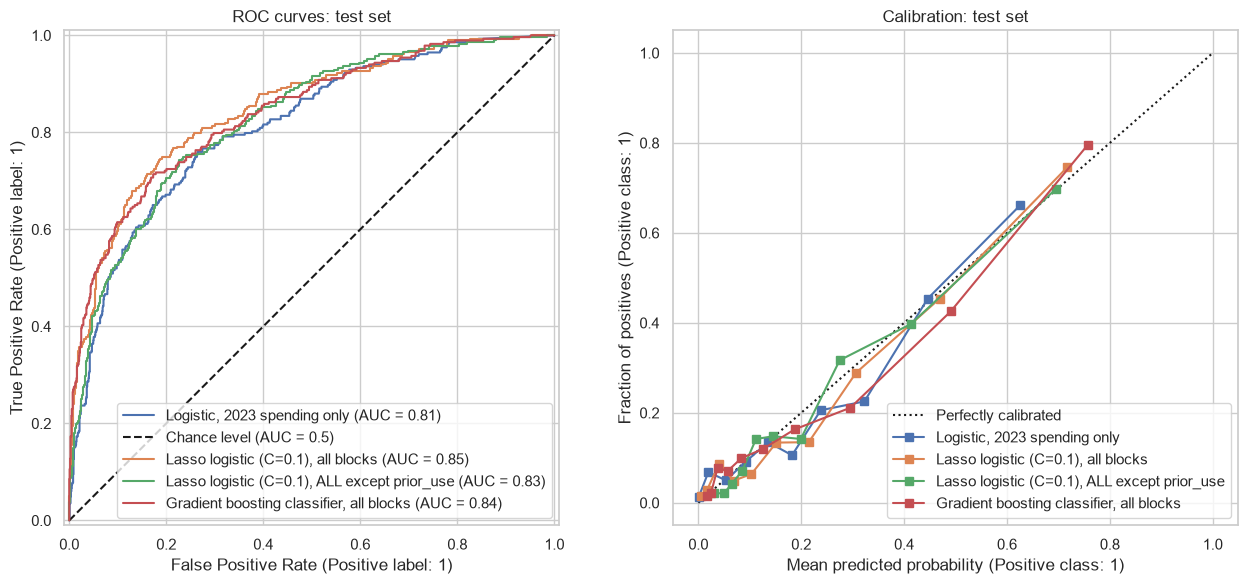

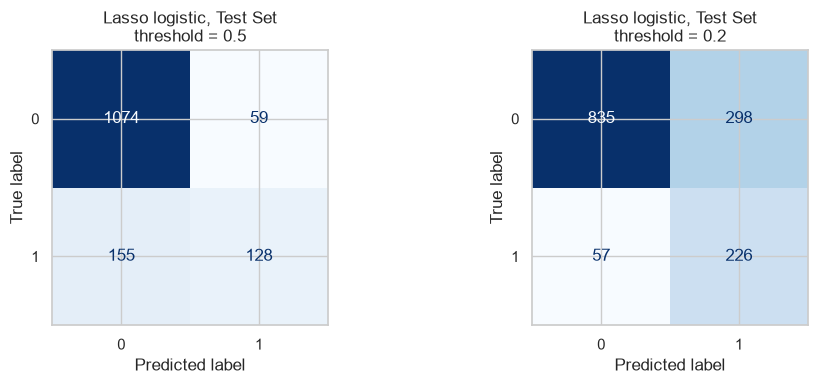

In [196]:
#classification on the test set
final_clf = {
    "Logistic, 2023 spending only": (make_logit(np.inf, 0, ["tot_exp_y1"]), ["tot_exp_y1"]),
    f"Lasso logistic (C={C_lasso}), all blocks": (make_logit(C_lasso, 1), all_predictors),
    f"Lasso logistic (C={C_lasso}), ALL except prior_use": (make_logit(C_lasso, 1, no_prior_cols), no_prior_cols),
    "Gradient boosting classifier, all blocks": (make_hgb_clf(), all_predictors),
}
flag_test = (X_test["tot_exp_y1"] >= cut_2023).astype(int)
#precision/recall: probability models use threshold 0.2 (the base rate)
rows = [{"model": "Base rate (no predictors)", "Test log loss": log_loss(yhigh_test, np.full(len(yhigh_test), base_rate)),
         "Test AUC": 0.5, "precision @0.2": np.nan, "recall @0.2": np.nan},
        {"model": "2023 top-20% flag (no fitting)", "Test log loss": np.nan, "Test AUC": roc_auc_score(yhigh_test, flag_test),
         "precision @0.2": precision_score(yhigh_test, flag_test), "Recall @0.2": recall_score(yhigh_test, flag_test)}]
test_probs = {}
for name, (model, cols) in final_clf.items():
    p = model.fit(X_train[cols], yhigh_train).predict_proba(X_test[cols])[:, 1]
    test_probs[name] = p
    rows.append({"model": name, "Test log loss": log_loss(yhigh_test, p), "Test AUC": roc_auc_score(yhigh_test, p),
                 "Precision @0.2": precision_score(yhigh_test, (p >= 0.2).astype(int)),
                 "Recall @0.2": recall_score(yhigh_test, (p >= 0.2).astype(int))})
test_clf_table = pd.DataFrame(rows).set_index("model")
display(test_clf_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for i, (name, p) in enumerate(test_probs.items()):
    RocCurveDisplay.from_predictions(yhigh_test, p, name=name, ax=axes[0], plot_chance_level=(i == 0))
    CalibrationDisplay.from_predictions(yhigh_test, p, n_bins=10, strategy="quantile", name=name, ax=axes[1])
axes[0].set_title("ROC curves: test set")
axes[1].set_title("Calibration: test set")
plt.tight_layout()
plt.show()

plot_confusion(yhigh_test, test_probs[f"Lasso logistic (C={C_lasso}), all blocks"], "Lasso logistic, Test Set")

**Notes**
* Log scale test R² is 0.531 for lasso and 0.539 for gradient boosting, roughly the same as their CV estimates (0.535 and 0.537), so the models were not overfit to the training folds. Both beat "next year = last year" (0.365) and the simple regression on 2023 spending (0.441).
* Without prior spending, test R² drops to 0.429 (lasso) and 0.498 (boosting). Boosting recovers much more of the lost accuracy, mostly through the conditions features such as number of conditions.
* When scaling the dollar, R² is much lower. Without prior spending, boosting reaches 0.15 and the lasso reaches −0.04, which is worse than predicting the average for everyone. Gradient boosting is best overall (dollar R² 0.28, MAE about $9,800). The 5 largest of the 1,416 test bills make up 37% of the dollar-scale total sum of squares. So small gaps, like lasso (0.19) vs the simple regression on 2023 spending (0.23), shouldn't be taken at face value. (The raw-dollar ridge has CV dollar R² 0.16 on the training set vs 0.20 on the test set) After the group factoring, the average predicted dollar amount is within about 10% of the actual average for every log model. A single factor would have multiplied lasso's predictions by about 20.
* "next year = last year" shows regression to the mean in dollars. It underpredicts the lowest deciles (all adults with $0 in 2023, averages close to $900 in 2024) and overpredicts the top decile. Lasso and boosting stay much closer to the diagonal across the range.
* Lasso logistic reaches test AUC 0.847 and Log Loss 0.356, matching its CV estimate (0.848 / 0.3605). Gradient boosting, which led in CV (AUC 0.855), lands slightly below lasso on the test set (0.839). Without prior spending, the lasso logistic still reaches test AUC 0.826. The calibration curves stay close to the diagonal.
* At threshold 0.2, the lasso model catches 80% of the test set's high-cost adults with precision 0.43. The "top 20% in 2023" rule catches 59% with precision 0.53.

**15. Interpretation (The Moment You've All Been Waiting For)**

On the test set, I shuffled all the columns of one block together, which breaks their link to the outcome while keeping their distribution, and measure how much test R² falls (this is called grouped permutation). A big drop means the fitted model relies on that block. This works for any model, including gradient boosting, which has no coefficients. 

Note: when blocks overlap (ex: prior spending and conditions), shuffling one block leaves the overlapping information available in the other, so importance spreads out the same way it does in the leave-one-out comparison. The drop can be larger than the model's R², since a model that leans heavily on a block makes confident, wrong predictions when that block is scrambled, which can push R² below zero.

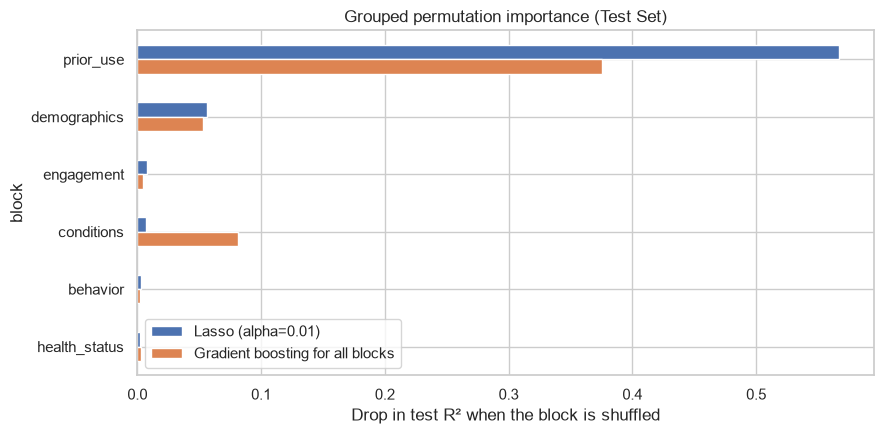

,Lasso (alpha=0.01),Gradient boosting for all blocks
block,,
prior_use,0.5669,0.3757
demographics,0.0567,0.0533
engagement,0.0077,0.0049
conditions,0.0068,0.0811
behavior,0.0028,0.0017
health_status,0.0021,0.0028


In [197]:
def grouped_permutation_importance(model, X, y, n_repeats=10, seed=random_seed):
    rng = np.random.default_rng(seed)
    base = r2_score(y, model.predict(X))
    rows = []
    for b, cols in blocks.items():
        cols = [c for c in cols if c in X.columns]
        if not cols:
            continue
        drops = []
        for _ in range(n_repeats):
            perm = rng.permutation(len(X))
            Xp = X.copy()
            for c in cols: #same shuffle for every column in the block
                Xp[c] = X[c].iloc[perm].set_axis(X.index)
            drops.append(base - r2_score(y, model.predict(Xp)))
        rows.append({"block": b, "R2 drop (mean)": np.mean(drops), "R2 drop (SD)": np.std(drops)})
    return pd.DataFrame(rows).set_index("block")

perm_tables = {}
for name in [best_linear, "Gradient boosting for all blocks"]:
    model_key = {"Gradient boosting for all blocks": "Gradient boosting, all blocks"}.get(name, name)
    if model_key not in fitted_final:
        raise KeyError(f"Model '{name}' not found in fitted_final. Available keys: {list(fitted_final)}")
    model, cols = fitted_final[model_key]
    perm_tables[name] = grouped_permutation_importance(model, X_test[cols], ylog_test)["R2 drop (mean)"]
perm_df = pd.DataFrame(perm_tables).sort_values(best_linear, ascending=False)

perm_df.plot.barh(figsize=(9, 4.5))
plt.gca().invert_yaxis()
plt.xlabel("Drop in test R² when the block is shuffled")
plt.title("Grouped permutation importance (Test Set)")
plt.tight_layout()
plt.show()
perm_df.round(4)

In [198]:
#ranked feature importance for the boosting model
model, cols = fitted_final["Gradient boosting, all blocks"]
pi = permutation_importance(model, X_test[cols], ylog_test, n_repeats=3, scoring="r2", n_jobs=-1,
                            random_state=random_seed)
(pd.DataFrame({"R2 drop (test)": pi.importances_mean, "block": [block_of[c] for c in cols]}, index=cols)
 .sort_values("R2 drop (test)", ascending=False).head(15).round(4))

,R2 drop (test),block
tot_exp_y1,0.1072,prior_use
n_conditions,0.0411,conditions
rx_exp_y1,0.0203,prior_use
n_chronic,0.0096,conditions
ob_visits_y1,0.0089,prior_use
race_eth,0.0079,demographics
region,0.0072,demographics
uninsured_all_year,0.0059,demographics
poverty_pct,0.0057,demographics
sex,0.0042,demographics


**Notes**
* Both final models lean on prior use far more than anything else. Shuffling the prior-use block drops test R² by 0.57 (lasso) and 0.38 (boosting). For lasso that is more than its total test R² (0.53), because scrambled spending makes the model confidently wrong. Demographics come second for lasso (0.06).
* Gradient boosting relies on conditions much more than lasso does (0.08 vs 0.007). After including 'tot_exp_y1', boosting's second most important column is 'n_conditions' (0.04 R²). It isn't among the 20 largest lasso coefficients from before, but boosting uses it largely as an "any 2023 medical event" feature. After that comes Rx spending, number of chronic condition, office visits, and several demographics (race, region, uninsured, income), much like lasso's largest coefficients.
* Engagement, health status, and behavior barely matter to either fitted model. 

In [199]:
#here we go
final_outcomes = pd.DataFrame({
    "R2 alone (CV, ridge)": alone_tbl["R2 alone"],
    "Share (CV, ridge)": Share,
    "R2 drop if removed (CV, ridge)": alone_tbl["R2 drop when removed"],
    "R2 drop if removed (CV, boosting)": alone_hgb["R2 drop when removed"],
    "Permutation drop (test, best linear)": perm_df[best_linear],
    "Permutation drop (test, boosting)": perm_df["Gradient boosting for all blocks"],
    "AUC alone (CV, logistic)": clf_blocks["AUC Alone"],
}).sort_values("Share (CV, ridge)", ascending=False)
final_outcomes.round(3)

,"R2 alone (CV, ridge)","Share (CV, ridge)","R2 drop if removed (CV, ridge)","R2 drop if removed (CV, boosting)","Permutation drop (test, best linear)","Permutation drop (test, boosting)","AUC alone (CV, logistic)"
prior_use,0.497,0.225,0.096,0.047,0.567,0.376,0.841
demographics,0.283,0.097,0.021,0.019,0.057,0.053,0.714
conditions,0.306,0.089,0.000,0.005,0.007,0.081,0.812
engagement,0.259,0.071,0.002,0.001,0.008,0.005,0.716
health_status,0.125,0.030,0.001,-0.000,0.002,0.003,0.729
behavior,0.103,0.022,0.001,-0.002,0.003,0.002,0.647



**Summary**

* Our best models explain about 53–54% of the variance in log 2024 spending on new data (test R² 0.53 for lasso, 0.54 for gradient boosting), up from 37% for "next year = last year" and 44% for a regression on 2023 spending alone. The median miss is about a factor of 3, but a minority of misses are huge, mostly adults who end up spending $0, and adults predicted to spend almost nothing who then spend a few thousand dollars.
* In dollars, test dollar R² is 0.19–0.28 for the all-block models, because a few very large, mostly unpredictable bills dominate dollar errors.
* For flagging the top 20% of spenders, test AUC is about 0.85, and at a 0.2 threshold we catch about 80% of next year's high-cost adults.
* With all blocks, the model family barely matters on the log scale. OLS, ridge, lasso, elastic net, splines, the two-part model, and gradient boosting all land within about 0.01 R² of each other. Without prior spending, boosting beats lasso by about 0.07 test R² (0.498 vs 0.429), and in dollars boosting is clearly best (0.28 vs 0.19).
* Prior spending and use predicts almost as well alone (CV R² of 0.50) as everything together (0.53), it has the largest share (42%), it is the only block whose removal costs a lot (R² of −0.10), and both final models rely on it most.
* Diagnosed conditions are second among the four types, but much of this comes from the conditions counts, which exist mostly for adults who had a 2023 medical event, so they partly measure prior use. Self-reported diagnoses alone are weaker (R² 0.21, AUC 0.75). Once prior spending is known, conditions add almost nothing.
* Healthcare engagement is third (13%). It helps most when prior spending is unavailable. About half of its standalone value comes from four SAQ items about care received in the last 12 months (visits, checkups, specialist, care rating). Those are partly measures of use and were partly collected in early 2024. Without them, engagement is roughly on par with health status.
* Health status is last (6%). Self-rated health, limitations, and the SF-12, K6, and PHQ-2 scores add little beyond diagnoses and spending.
* Demographics carry information no other block provides, and insurance is only part of it.
* Without the prior-use block, the other blocks recover about 82% (linear) to 91% (gradient boosting) of the full model's R². But part of that, and most of boosting's edge over the linear model, comes from condition counts that double as an "any 2023 care" signal. Without those as well, the models keep about 78–79% (R² of 0.415 / 0.425), and about 74–75% (0.395 / 0.404) without the self-reported items. If only the 2023 dollar amounts are removed and visit/fill counts are kept, they keep about 93–95%.

**Limitations**
*  MEPS surveys include weights, strata, clusters, and we used none of it. The results describe this sample of 7,079 adults, not the U.S. population, and the CV folds ignore clustering within households.
* The SAQ was partly completed in early 2024, and the diagnosis values can include answers from interviews in early 2024. The robustness checks show that removing these items barely changes the headline results, but they are still not exclusively 2023 information.
* The conditions counts and several engagement items are partly indirect measures of 2023 use, so "which type matters" depends partly on how the blocks are defined.
* Dollar accuracy is limited. Large bills are rare and hard to predict, and a handful of them dominate dollar-scale R².

**To Do Later**
* Try an evaluation with survey rates (weighted R² / AUC)?
* Try a gradient boosting model on raw dollars with a Poisson loss?
* Tune boosting more (maybe try a random forest?)
* We could try splitting the conditions block into self-reported diagnoses and conditions counts in the main analysis and moving the four SAQ care items into the use block.
* Check accuracy in subgroups to see whether the models work equally well for everyone.
* Add interactions suggested by the boosting model to the linear models.

**Sources I Referenced That Weren't From Class**
* [Gradient Boosting Machines](https://uc-r.github.io/gbm_regression)
* [MEPS Cost Model](https://github.com/Jessmatth/meps-cost-model)
* [Compute Variable Importance Using Shapley R2 Values](https://barbaratarantino.github.io/SEMdeep/reference/getShapleyR2.html)
* [Retransformation Bias, Duan Smearing Estimator, and When To Use It](https://talkcodetome.com/stats/Retransformation-Bias-Duan-Smearing-Estimator/)